## **ANALYSE DE DONNEES DE CONSOMMATION ENERGETIQUE DE TETOUAN (MAROC)**

### Contexte et Objectifs du projet
On se chargera d’analyser les données de consommation en énergie de la ville de Tétouan qui sera divisé en trois zones: Quads, Smir et Boussafou. La consommation en énergie de ces zones a été enregistrée chaque 10 minutes pendant un an. Ont été aussi relevés, la température en °C, l’humidité en %, la vitesse du vent, les flux diffus et flux diffus généraux en W/m². Les objectifs que nous nous fixons pour ce projet sont :
    	**Comprendre les tendances de consommation énergétique dans trois zones**
    	**Identifier les raisons des pics de consommation énergétique**
    	**Identifier les raisons des pics de consommation énergétique**
        **Formuler des recommandations sur la gestion énergétiques basées sur les résultats d'analyse**
Notre analyse sera scindée en cinq étapes. Une phase de traitement des données brutes obtenues, une étape descriptive, une analyse diagnostique, une analyse prédictive et enfin une analyse prescriptive

## **ETAPE 1: CHARGEMENT ET TRAITEMENT DES DONNEES**.

In [1]:

#IMPORTATION DES BIBLIOTHEQUES NECESSAIRES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### ETAPE 1: CHARGEMENT ET TRAITEMENT DES DONNEES

In [ ]:
from pathlib import Path
data_path = Path("powerconsumption.csv")
data = pd.read_csv(data_path)

In [4]:
data.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [5]:
data.tail()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
52411,12/30/2017 23:10,7.010,72.4,0.080,0.040,0.096,31160.45627,26857.31820,14780.31212
52412,12/30/2017 23:20,6.947,72.6,0.082,0.051,0.093,30430.41825,26124.57809,14428.81152
52413,12/30/2017 23:30,6.900,72.8,0.086,0.084,0.074,29590.87452,25277.69254,13806.48259
52414,12/30/2017 23:40,6.758,73.0,0.080,0.066,0.089,28958.17490,24692.23688,13512.60504
52415,12/30/2017 23:50,6.580,74.1,0.081,0.062,0.111,28349.80989,24055.23167,13345.49820


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  object 
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB


In [7]:
data.isnull().sum()

Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

In [8]:
data.duplicated().value_counts()

False    52416
Name: count, dtype: int64

In [9]:
renommer_colon = {
    'Datetime': 'Date_Heure',
    'Temperature': 'Température °C',
    'Humidity': 'Humidité %',
    'WindSpeed': 'Vitesse_Vent m/s',
    'GeneralDiffuseFlows': 'Flux_Diffus_Généraux W/m²',
    'DiffuseFlows': 'Flux_Diffus W/m²',
    'PowerConsumption_Zone1': 'Consommation_Zone_1 kW',
    'PowerConsumption_Zone2': 'Consommation_Zone_2 kW',
    'PowerConsumption_Zone3': 'Consommation_Zone_3 kW'
}

data = data.rename(columns= renommer_colon)

In [10]:
data.head()

,Date_Heure,Température °C,Humidité %,Vitesse_Vent m/s,Flux_Diffus_Généraux W/m²,Flux_Diffus W/m²,Consommation_Zone_1 kW,Consommation_Zone_2 kW,Consommation_Zone_3 kW
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


Créons les jours de la semaine et mois à partir de la date pour permettre une analyse plus approfondie

In [11]:
## Convertissons d'abord Date_Heure en format datetime
data['Date_Heure'] = pd.to_datetime(data['Date_Heure'], errors='coerce')

data['Jour'] = data['Date_Heure'].dt.day_name()   
data['Mois'] = data['Date_Heure'].dt.month_name() 
data['Heure'] = data['Date_Heure'].dt.hour        

In [12]:
# Affichons les jours et mois en français pour faciliter l'analyse
import locale
locale.setlocale(locale.LC_TIME, 'fr_FR.UTF-8')  
# pour avoir la langue du système d'exploitation et pas python

data['Jour'] = data['Date_Heure'].dt.strftime('%A')   
data['Mois'] = data['Date_Heure'].dt.strftime('%B')   

In [13]:
#Vérifions si les modifications ont été apportées
data["Mois"].unique()

array(['janvier', 'fÃ©vrier', 'mars', 'avril', 'mai', 'juin', 'juillet',
       'aoÃ»t', 'septembre', 'octobre', 'novembre', 'dÃ©cembre'],
      dtype=object)

In [14]:
# Les caractères spéciaux comme les accents ne semble pas être pris en compte donc essayons de créer un dictionnaires avec le bon orthographe
data['Mois_num'] = data['Date_Heure'].dt.month

mois = {
    1: 'Janvier', 2: 'Février', 3: 'Mars', 4: 'Avril',
    5: 'Mai', 6: 'Juin', 7: 'Juillet', 8: 'Août',
    9: 'Septembre', 10: 'Octobre', 11: 'Novembre', 12: 'Décembre'
}

data['Mois'] = data['Mois_num'].map(mois)


In [15]:
#Vérifions les noms de colonnes
print(data["Mois"].unique())

['Janvier' 'Février' 'Mars' 'Avril' 'Mai' 'Juin' 'Juillet' 'Août'
 'Septembre' 'Octobre' 'Novembre' 'Décembre']


In [16]:
#Supprimons les colonnes Date_Heure et Mois_num qui ne seront plus utiles
data=data.drop(["Date_Heure", "Mois_num"], axis=1)


In [17]:
#Arrondissons les valeurs de consommation dans les zones pour faciliter l'analyse qui va suivre
data["Consommation_Zone_1 kW"]=data["Consommation_Zone_1 kW"].round(0).astype(int)
data["Consommation_Zone_2 kW"]=data["Consommation_Zone_2 kW"].round(0).astype(int)
data["Consommation_Zone_3 kW"]=data["Consommation_Zone_3 kW"].round(0).astype(int)

In [18]:
data.head(2)

,Température °C,Humidité %,Vitesse_Vent m/s,Flux_Diffus_Généraux W/m²,Flux_Diffus W/m²,Consommation_Zone_1 kW,Consommation_Zone_2 kW,Consommation_Zone_3 kW,Jour,Mois,Heure
0,6.559,73.8,0.083,0.051,0.119,34056,16129,20241,dimanche,Janvier,0
1,6.414,74.5,0.083,0.070,0.085,29815,19375,20131,dimanche,Janvier,0


In [19]:
data.head(5)

,Température °C,Humidité %,Vitesse_Vent m/s,Flux_Diffus_Généraux W/m²,Flux_Diffus W/m²,Consommation_Zone_1 kW,Consommation_Zone_2 kW,Consommation_Zone_3 kW,Jour,Mois,Heure
0,6.559,73.8,0.083,0.051,0.119,34056,16129,20241,dimanche,Janvier,0
1,6.414,74.5,0.083,0.070,0.085,29815,19375,20131,dimanche,Janvier,0
2,6.313,74.5,0.080,0.062,0.100,29128,19007,19668,dimanche,Janvier,0
3,6.121,75.0,0.083,0.091,0.096,28229,18361,18899,dimanche,Janvier,0
4,5.921,75.7,0.081,0.048,0.085,27336,17872,18442,dimanche,Janvier,0


##### **SYNTHESE DE L'ETAPE 1**
Les données ont été récupérées du 1/1/2017 au 30/12/2017, il y a 9 colonnes et 52416 observations. Il n'y a ni données manquantes ni doublons. Nous avons fait une traduction en français pour faciliter l’interprétation. Trois nouvelles colonnes ont été créées (Jour, Mois et Heure). Les valeurs pour la consommation ont été arrondies pour obtenir des entiers et faciliter surtout la visualisation plus tard. Les unités ont aussi été ajoutées pour chaque variables. Les données sont maintenant prêtes pour la suite.

## **ETAPE 2: ANALYSE DESCRIPTIVE**
OBJECTIF:
- Comprendre les tendances de consommations énergétiques dans les trois zones et suivant l'année
- Représenter les variations des conditions météorologiques dans le temps. Dans cette étape le but est juste de repérer et visualiser et avoir une idée des tendances que suivent nos variables.



In [20]:
data.describe()

,Température °C,Humidité %,Vitesse_Vent m/s,Flux_Diffus_Généraux W/m²,Flux_Diffus W/m²,Consommation_Zone_1 kW,Consommation_Zone_2 kW,Consommation_Zone_3 kW,Heure
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.972966,21042.506925,17835.407032,11.500000
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562440,5201.465261,6622.166715,6.922253
min,3.247000,11.340000,0.050000,0.004000,0.011000,13896.000000,8560.000000,5935.000000,0.000000
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26311.000000,16980.750000,13129.000000,5.750000
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32266.000000,20823.000000,16415.000000,11.500000
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.000000,24714.000000,21624.000000,17.250000
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.000000,37409.000000,47598.000000,23.000000


Visualisons la situation pour chaque zone

In [21]:
# Créeons d(abord u dataframe avec uniquement la énergetique consommation pour chaque zone)
data_Cons_Zone = pd.melt(
    data,
    value_vars=["Consommation_Zone_1 kW", "Consommation_Zone_2 kW", "Consommation_Zone_3 kW"],
    var_name="Zones",
    value_name="Consommation"
)

In [22]:
data_Cons_Zone

,Zones,Consommation
0,Consommation_Zone_1 kW,34056
1,Consommation_Zone_1 kW,29815
2,Consommation_Zone_1 kW,29128
3,Consommation_Zone_1 kW,28229
4,Consommation_Zone_1 kW,27336
...,...,...
157243,Consommation_Zone_3 kW,14780
157244,Consommation_Zone_3 kW,14429
157245,Consommation_Zone_3 kW,13806
157246,Consommation_Zone_3 kW,13513


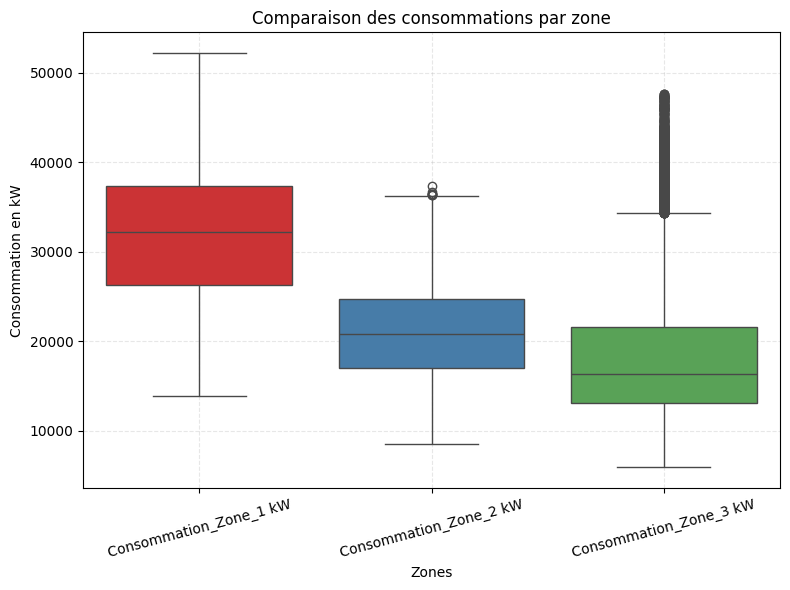

In [23]:
# Créeons un visuel des informations déjè fournies par  la fonction .describe
plt.figure(figsize=(8, 6))
sns.boxplot(x="Zones", y="Consommation", data=data_Cons_Zone, hue="Zones", palette="Set1")
plt.title("Comparaison des consommations par zone")
plt.ylabel("Consommation en kW")
plt.xlabel("Zones")
plt.xticks(rotation=15)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


Interprétation du boxplot: 
La consommation moyenne est différente pour chaque zone. La Zone 1 enregistre des valeurs nettement plus élevées que les autres. Les trois zones ont des consommations moyennes respectives de 32344, 21042 et 17835.

In [24]:
# Voyons comment la consommation varie en fonction des jours de la semaine 
# Créeons d'abord un dataframe avec la consommation, les différentes zones et les jours de la semaine
data_Cons_ZoneJ = pd.melt(
    data,
    id_vars="Jour",
    value_vars=["Consommation_Zone_1 kW", "Consommation_Zone_2 kW", "Consommation_Zone_3 kW"],
    var_name="Zones",
    value_name="Consommation")

data_Cons_ZoneJ

,Jour,Zones,Consommation
0,dimanche,Consommation_Zone_1 kW,34056
1,dimanche,Consommation_Zone_1 kW,29815
2,dimanche,Consommation_Zone_1 kW,29128
3,dimanche,Consommation_Zone_1 kW,28229
4,dimanche,Consommation_Zone_1 kW,27336
...,...,...,...
157243,samedi,Consommation_Zone_3 kW,14780
157244,samedi,Consommation_Zone_3 kW,14429
157245,samedi,Consommation_Zone_3 kW,13806
157246,samedi,Consommation_Zone_3 kW,13513


In [25]:
## Regroupons par moyenne de consommation par jour pour une meilleur représentation graphique
moyennes_Jour = data_Cons_ZoneJ.groupby(["Zones", "Jour"])["Consommation"].mean().round(0).astype(int).reset_index()
jours_ordre = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
moyennes_Jour["Jour"] = pd.Categorical(moyennes_Jour["Jour"], categories=jours_ordre, ordered=True)

moyennes_Jour

,Zones,Jour,Consommation
0,Consommation_Zone_1 kW,dimanche,30780
1,Consommation_Zone_1 kW,jeudi,32842
2,Consommation_Zone_1 kW,lundi,32615
3,Consommation_Zone_1 kW,mardi,32713
4,Consommation_Zone_1 kW,mercredi,32872
5,Consommation_Zone_1 kW,samedi,32253
6,Consommation_Zone_1 kW,vendredi,32339
7,Consommation_Zone_2 kW,dimanche,18979
8,Consommation_Zone_2 kW,jeudi,21845
9,Consommation_Zone_2 kW,lundi,21280


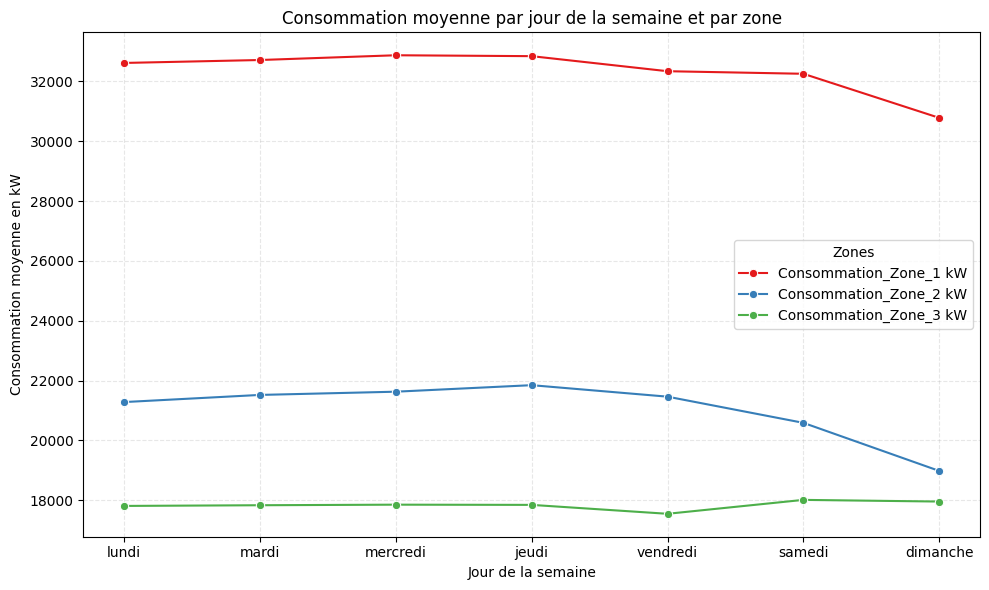

In [26]:
# Passons à la représentation graphique de la consommation par jour et par zone
plt.figure(figsize=(10, 6))
sns.lineplot(data=moyennes_Jour, x='Jour', y='Consommation', hue='Zones', marker='o', palette='Set1')
plt.title('Consommation moyenne par jour de la semaine et par zone')
plt.ylabel('Consommation moyenne en kW')
plt.xlabel('Jour de la semaine')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Pour toutes les zones, la consommation moyenne diminue en s'approchant du week end sauf pour la zone 3 où le creux apparait le vendredi.

Maintenant représentons la tendance mensuelle.

In [27]:
# Essayons aussi d'inclure la consommation par mois dans un dataframe
data_Cons_ZoneM = pd.melt(
    data,
    id_vars="Mois",
    value_vars=["Consommation_Zone_1 kW", "Consommation_Zone_2 kW", "Consommation_Zone_3 kW"],
    var_name="Zones",
    value_name="Consommation")


data_Cons_ZoneM

,Mois,Zones,Consommation
0,Janvier,Consommation_Zone_1 kW,34056
1,Janvier,Consommation_Zone_1 kW,29815
2,Janvier,Consommation_Zone_1 kW,29128
3,Janvier,Consommation_Zone_1 kW,28229
4,Janvier,Consommation_Zone_1 kW,27336
...,...,...,...
157243,Décembre,Consommation_Zone_3 kW,14780
157244,Décembre,Consommation_Zone_3 kW,14429
157245,Décembre,Consommation_Zone_3 kW,13806
157246,Décembre,Consommation_Zone_3 kW,13513


In [28]:

# Faisons la même chose pour pouvoir représenter la consommation par mois 
moyennes_Mois = data_Cons_ZoneM.groupby(["Zones", "Mois"])["Consommation"].mean().round(0).astype(int).reset_index()
mois_ordre = ['Janvier', 'Février', 'Mars', 'Avril', 'Mai', 'Juin', 'Juillet', 'Août','Septembre', 'Octobre', 'Novembre', 'Décembre']
moyennes_Mois["Mois"] = pd.Categorical(moyennes_Mois["Mois"], categories=mois_ordre, ordered=True)

moyennes_Mois

,Zones,Mois,Consommation
0,Consommation_Zone_1 kW,Août,36435
1,Consommation_Zone_1 kW,Avril,31170
2,Consommation_Zone_1 kW,Décembre,29024
3,Consommation_Zone_1 kW,Février,30986
4,Consommation_Zone_1 kW,Janvier,31032
5,Consommation_Zone_1 kW,Juillet,35832
6,Consommation_Zone_1 kW,Juin,34606
7,Consommation_Zone_1 kW,Mai,32396
8,Consommation_Zone_1 kW,Mars,31155
9,Consommation_Zone_1 kW,Novembre,29002


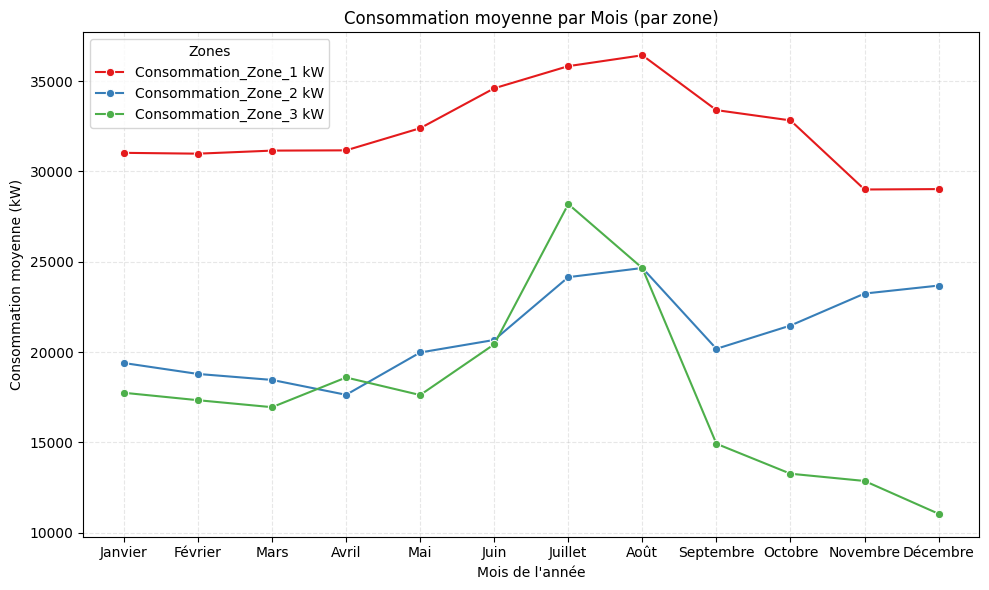

In [29]:
#Représentation graphique de toute les zones en même temps
plt.figure(figsize=(10, 6))
sns.lineplot(data=moyennes_Mois, x='Mois', y='Consommation', hue='Zones', marker='o', palette='Set1')
plt.title('Consommation moyenne par Mois (par zone)')
plt.ylabel('Consommation moyenne (kW)')
plt.xlabel("Mois de l'année")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Pour toutes les zones, la tendance est la même. La consommation énergetiques commence à significativement augmenter vers le mois 
de Mai pour atteindre ses valeurs les plus élevées de l'année entre Juillet et Août. On remarque ensuite une baisse en Septembre qui ne continue que pour la zone 3.

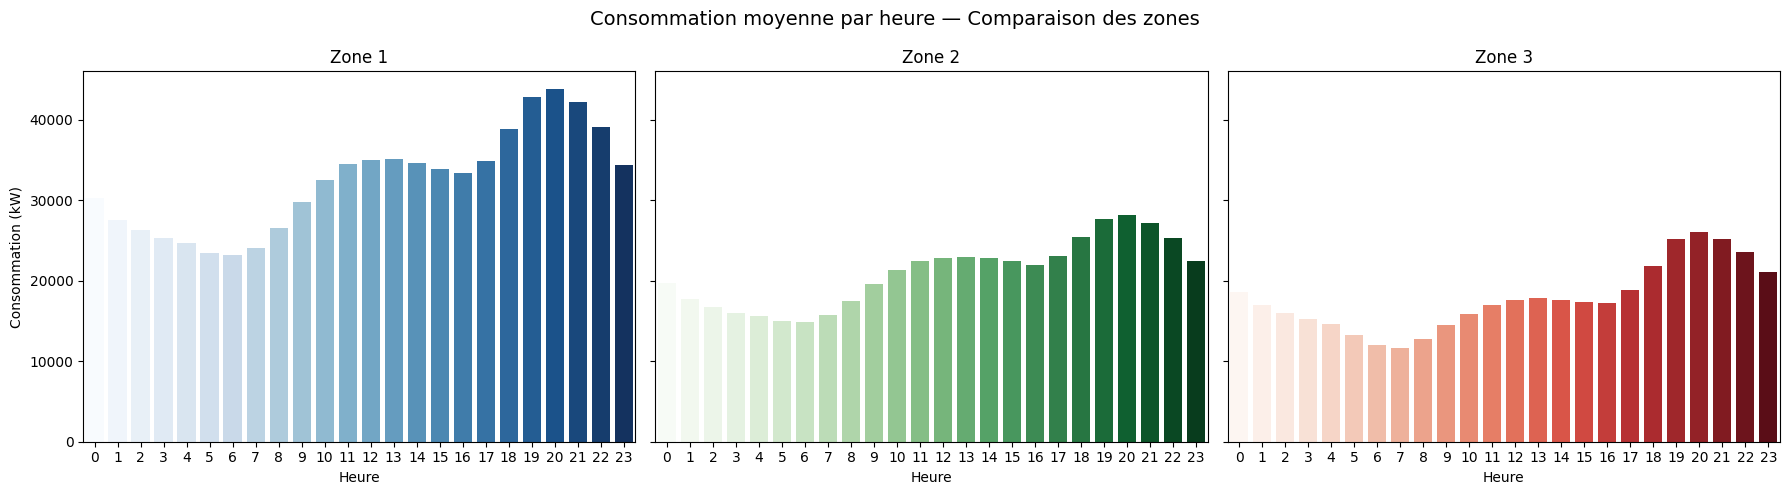

In [30]:

# Step 1: Group by 'Heure' for each zone
moy_heure_1 = data.groupby('Heure')['Consommation_Zone_1 kW'].mean()
moy_heure_2 = data.groupby('Heure')['Consommation_Zone_2 kW'].mean()
moy_heure_3 = data.groupby('Heure')['Consommation_Zone_3 kW'].mean()

# Step 2: Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Step 3: Plot for each zone
sns.barplot(x=moy_heure_1.index, y=moy_heure_1.values,hue= moy_heure_1.index, palette="Blues", legend=False, ax=axes[0])
axes[0].set_title("Zone 1")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Consommation (kW)")

sns.barplot(x=moy_heure_2.index, y=moy_heure_2.values, hue= moy_heure_1.index, palette="Greens",legend=False, ax=axes[1])
axes[1].set_title("Zone 2")
axes[1].set_xlabel("Heure")
axes[1].set_ylabel("")

sns.barplot(x=moy_heure_3.index, y=moy_heure_3.values, hue= moy_heure_1.index, palette="Reds", legend=False, ax=axes[2])
axes[2].set_title("Zone 3")
axes[2].set_xlabel("Heure")
axes[2].set_ylabel("")

# Final layout adjustments
plt.suptitle("Consommation moyenne par heure — Comparaison des zones", fontsize=14)
plt.tight_layout()
plt.show()



Le barplot montre une consommation énergetique qui augmente en milieu de journée, mais le pic est noté entre 19h et 21h. La valeur moyenne la plus élevé est enregistrée à 20h.

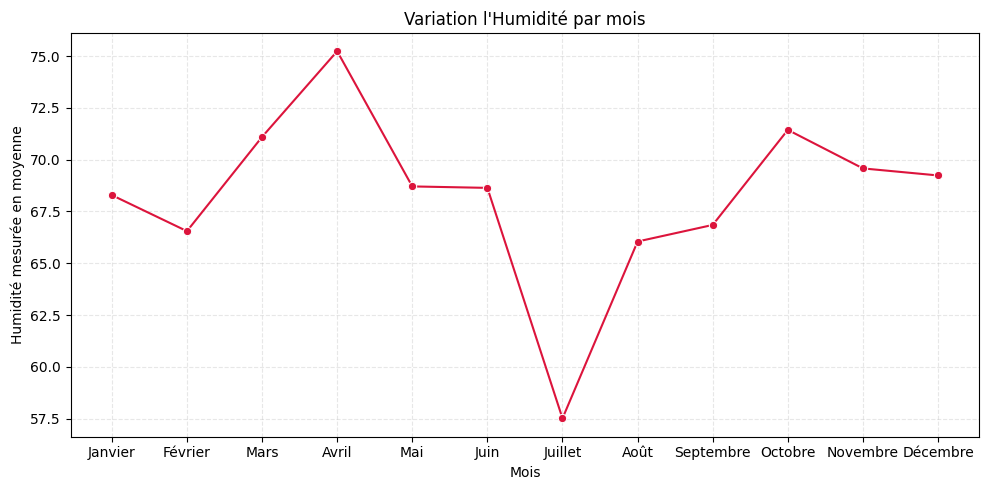

In [31]:
# Maintenant passons au conditions météorologique comme l'humidité pour chaque mois
humid_moy = data.groupby('Mois')['Humidité %'].mean().round(2).reset_index()


humid_moy['Mois'] = pd.Categorical(humid_moy['Mois'], categories=mois_ordre, ordered=True)

plt.figure(figsize=(10, 5))
sns.lineplot(data=humid_moy, x='Mois', y='Humidité %', marker='o', color='crimson')
plt.title("Variation l'Humidité par mois")
plt.ylabel("Humidité mesurée en moyenne")
plt.xlabel("Mois")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Tout au long de l'année, les valeurs les plus basses ont été enregistrées entre Mai et Septembre. Elles remontent après ça avec un pic entre Mars et Avril.

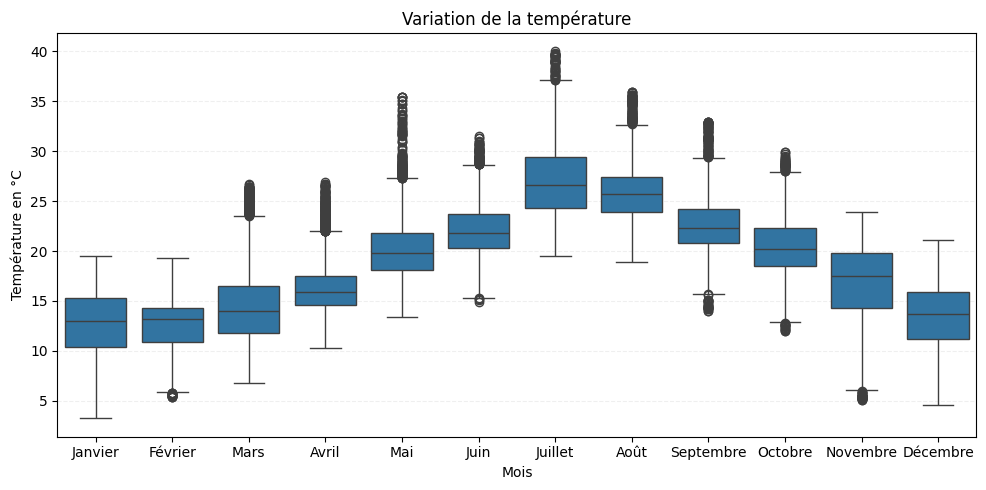

In [32]:
""" Passons à la température observée pour chaque mois grâce à un boxplot, ça nous permettra de repérer les outliers et 
l'évolution en moyenne"""
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x='Mois', y='Température °C')
plt.title("Variation de la température")
plt.ylabel("Température en °C")
plt.xlabel("Mois")
plt.grid(axis='y', linestyle='--', alpha=0.2)
plt.tight_layout()
plt.show()


Les températures les plus élevées sont enregistrées entre Juin et Septembre avec un pic en Juilliet.

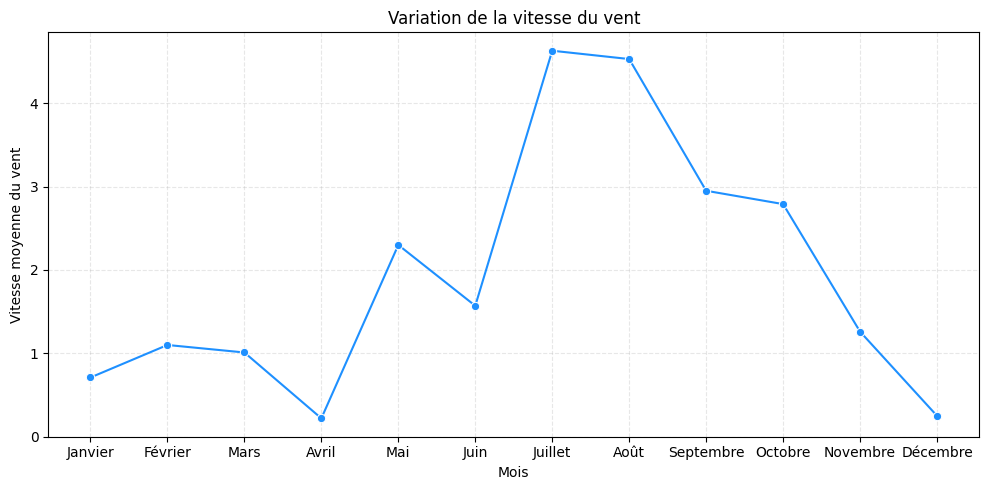

In [33]:
# Etudions aussi l'évolution de la vitesse du vent au cours des mois
vent_moy = data.groupby('Mois')['Vitesse_Vent m/s'].mean().round(2).reset_index()

vent_moy['Mois'] = pd.Categorical(vent_moy['Mois'], categories=mois_ordre, ordered=True)

plt.figure(figsize=(10, 5))
sns.lineplot(data=vent_moy, x='Mois', y='Vitesse_Vent m/s', marker='o', color='dodgerblue')
plt.title("Variation de la vitesse du vent")
plt.ylabel("Vitesse moyenne du vent")
plt.xlabel("Mois")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

La vitesse du vent aussi varie au cours de l'année avec valeurs plus importantes entre Juillet et Septembre

Text(0.5, 0, 'Mois')

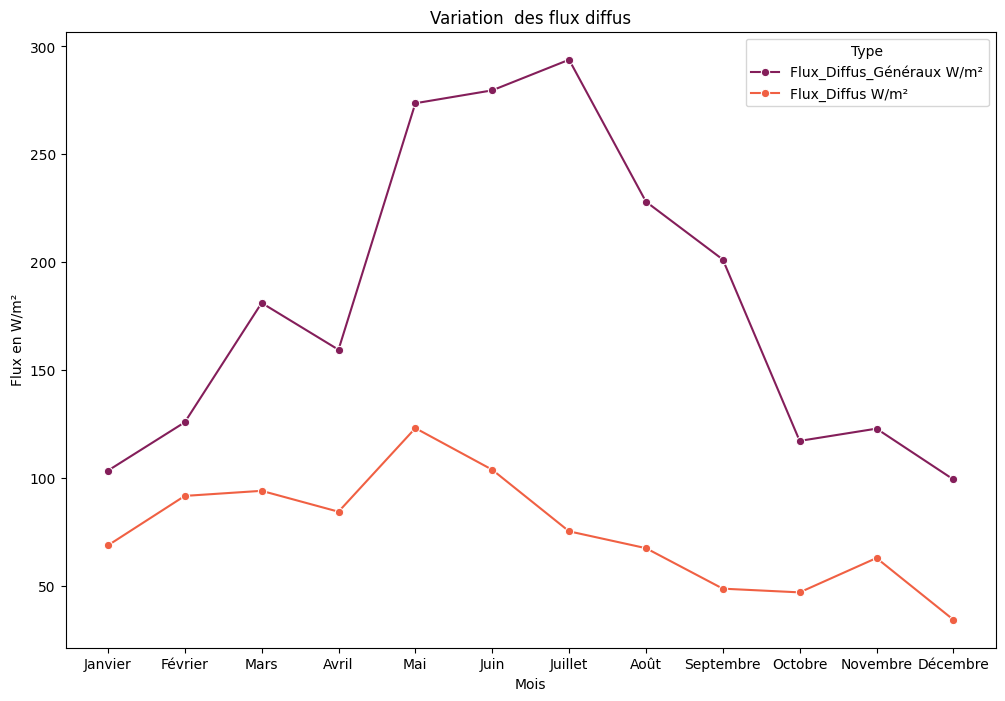

In [34]:
# simultannément visualisons le flux diffus et le flux diffus général
dif_moy = data.groupby('Mois')[["Flux_Diffus_Généraux W/m²", "Flux_Diffus W/m²"]].mean().reset_index()

dif_mois = pd.melt(dif_moy, id_vars='Mois', var_name='Type', value_name='Valeur')

dif_mois['Mois'] = pd.Categorical(dif_mois['Mois'], categories=mois_ordre, ordered=True)

plt.figure(figsize=(12, 8))
sns.lineplot(data=dif_mois, x='Mois', y='Valeur', hue='Type', marker='o', palette='rocket')
plt.title("Variation  des flux diffus")
plt.ylabel("Flux en W/m²")
plt.xlabel("Mois")

Les flux diffus suivent la même tendance, donc une augmentatio des valeurs entre

SYNTHESE DE L'ETAPE 2: 
Dans la partie descriptive, nous avons noter les sens de fluctuations des conditions environnementales et de la consommation énergetiques.
Maintenant réalisons une analyse diagnostique pour comprendre les raisons derrières les variations de consommation.

## ETAPE 3: ANALYSE DIAGNOSTIQUE
OBJECTIF: Identifier les raisons des pics de consommation énergétique à travers une analyse diagnostique.

OBJECTIF: Identifier les raisons des pics de consommation énergétique à travers une analyse diagnostique.
-	L'analyse diagnostique nous permettra de comprendre les variations notées au niveau de la consommation énergétiques pour les trois zones.
-	Nous utiliserons le test d'Anova pour voir si les jours et les mois ont un impact sur la consommation.
-	Dans le but d'identifier les raisons des pics de consommation, nous commencerons d'abord par analyser le rapport entre les conditions météorologiques (Température, humidité, etc.),l'heure et la consommation énergétique pour cela nous utiliserons la régression linéaire multiple comme technique statistique.
-	Après cela il sera intéressant de voir s'il y a des jours de la semaine ou des mois en particulier qui influent plus sur la consommation que d'autres pour chaque zone.
-	Il sera aussi analysé les conditions notées autour des pics de consommations lorsqu'ils sont enregistrés.


#### Régression Multiple entre consommation et conditions météorologiques

Pour effectuer la régression linéaire nous utiliserons la consommation comme variable à expliquer et toutes les autres variables quantitatives comme variables explicatives.
Pour commencer, nous allons vérifier qu'il n'y a pas de correlation entre les variables explicatives.

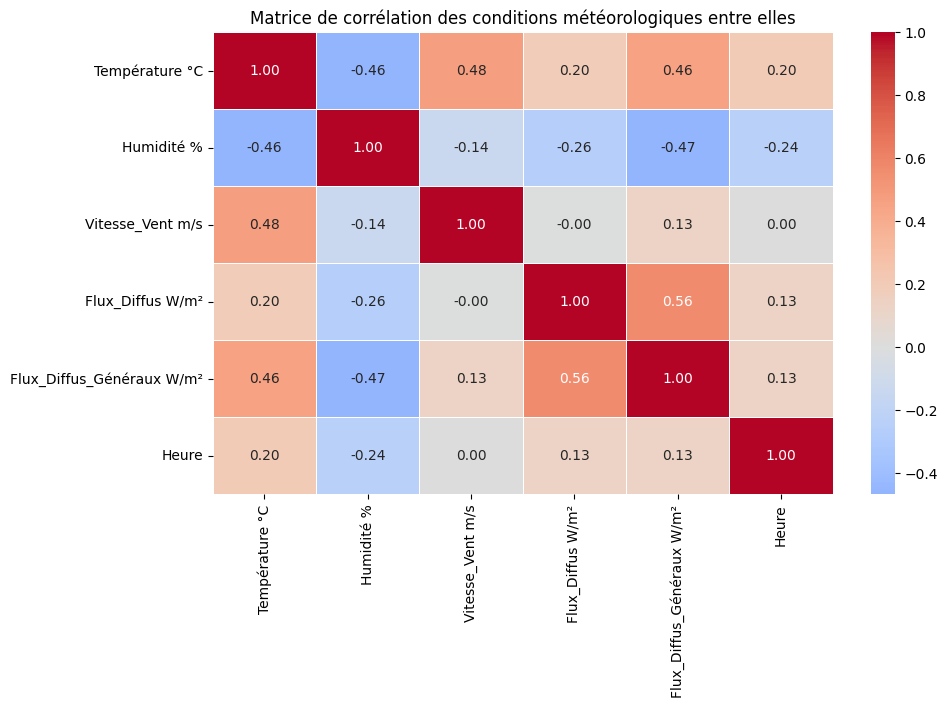

In [35]:
# Définissons nos variables quantitaives
variables_quantitatives = data[[
    "Température °C",
    "Humidité %",
    "Vitesse_Vent m/s",
    "Flux_Diffus W/m²",
    "Flux_Diffus_Généraux W/m²",
    "Heure"
]]

# Création de la matrice de corrélation avec la méthode de Pearson
corr_matrix = variables_quantitatives.corr(method='pearson')  


plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f", linewidths=0.5)
plt.title("Matrice de corrélation des conditions météorologiques entre elles")
plt.show()


Le heatmap montre clairement qu'il n'y a pas de forte corrélation entre les variables elles même donc on peut passer à la régression 
linéaire avec la consommation pour chaque zone.

In [36]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


Variables_quant = ["Température °C", "Humidité %", "Vitesse_Vent m/s", 
            "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]

# Copie des données et standardisation
data_scaled = data.copy()
scaler = StandardScaler()
data_scaled[Variables_quant] = scaler.fit_transform(data_scaled[Variables_quant])

X = data_scaled[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y = data["Consommation_Zone_1 kW"]  


model_1 = LinearRegression()
model_1.fit(X, y)

coeffs = pd.DataFrame({
    "Variable_1": X.columns,
    "Coefficient_1": model_1.coef_
})


X2 = data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y2 = data["Consommation_Zone_2 kW"]  


model_2 = LinearRegression()
model_2.fit(X2, y2)

coeffs_2 = pd.DataFrame({
    "Variable_2": X2.columns,
    "Coefficient_2": model_2.coef_
})


X3 = data_scaled[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²","Heure"]]
y3 = data["Consommation_Zone_3 kW"]  


model_3 = LinearRegression()
model_3.fit(X3, y3)

coeffs_3 = pd.DataFrame({
    "Variable_3": X3.columns,
    "Coefficient_3": model_3.coef_
})



In [37]:
print("Résultat pour la Zone 1") 
print(coeffs)

print("Résultat pour la Zone 2") 
print(coeffs_2)

print("Résultat pour la Zone 3") 
print(coeffs_3)


Résultat pour la Zone 1
                  Variable_1  Coefficient_1
0             Température °C    2280.687947
1                 Humidité %      29.408324
2           Vitesse_Vent m/s      99.910969
3           Flux_Diffus W/m²    -454.394801
4  Flux_Diffus_Généraux W/m²     -78.659224
5                      Heure    4817.499851
Résultat pour la Zone 2
                  Variable_2  Coefficient_2
0             Température °C     224.747063
1                 Humidité %     -19.831589
2           Vitesse_Vent m/s      40.183949
3           Flux_Diffus W/m²      -3.789379
4  Flux_Diffus_Généraux W/m²      -0.339432
5                      Heure     460.952648
Résultat pour la Zone 3
                  Variable_3  Coefficient_3
0             Température °C    3069.331782
1                 Humidité %    -104.442351
2           Vitesse_Vent m/s     503.571259
3           Flux_Diffus W/m²    -598.251251
4  Flux_Diffus_Généraux W/m²   -1109.203296
5                      Heure    2598.125780


-   Zone 1 – Coefficients standardisés
-	La température est la variable la plus influente avec un coefficient de 2280 : une augmentation d’un écart-type de température entraîne la plus forte augmentation relative de la consommation.*
-	Les heures de la journée ont un effet encore plus fort. Ce qui veut dire une activité très importante en journée dans la zone 1.
Zone 2
-	La température est aussi le facteur principal qui explique la consommation.
-	Les heures suivent avec un coefficient de 460.
Zone 3
-	Encore une fois la température est le facteur dominant.
-	L'heure impacte moins que dans les autres zones En général la vitesse du vent a un impact secondaire. L'effet des flux est négligeable sauf pour la zone 3 ou les flux généraux sont un peu plus important.


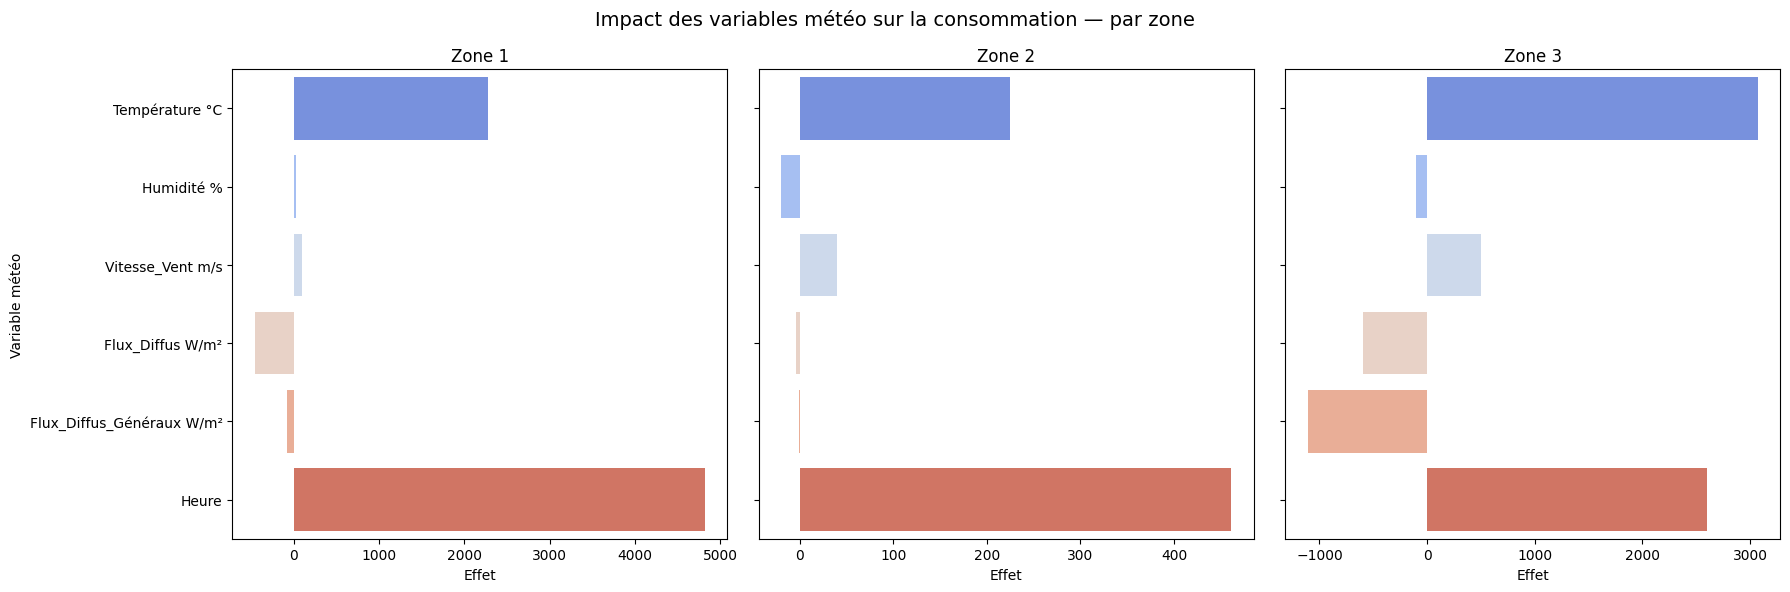

In [38]:
# Essayons de visualiser les plots côte à côte pour une meilleur comparaison et analyse 
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Zone 1
sns.barplot(
    x="Coefficient_1", y="Variable_1",
    data=coeffs, hue="Variable_1", palette="coolwarm", legend=False, ax=axes[0]
)
axes[0].set_title("Zone 1")
axes[0].set_xlabel("Effet")
axes[0].set_ylabel("Variable météo")

# Zone 2
sns.barplot(
    x="Coefficient_2", y="Variable_2",
    data=coeffs_2, hue="Variable_2", palette="coolwarm", legend=False, ax=axes[1]
)
axes[1].set_title("Zone 2")
axes[1].set_xlabel("Effet")
axes[1].set_ylabel("")

# Zone 3
sns.barplot(
    x="Coefficient_3", y="Variable_3",
    data=coeffs_3, hue="Variable_3", palette="coolwarm", legend=False, ax=axes[2]
)
axes[2].set_title("Zone 3")
axes[2].set_xlabel("Effet")
axes[2].set_ylabel("")

# Final layout
plt.suptitle("Impact des variables météo sur la consommation — par zone", fontsize=14)
plt.tight_layout()
plt.show()



In [39]:

Variables_quant = ["Température °C", "Humidité %", "Vitesse_Vent m/s", 
            "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]



X = data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y = data["Consommation_Zone_1 kW"]  


model_1 = LinearRegression()
model_1.fit(X, y)

coeffs = pd.DataFrame({
    "Variable_1": X.columns,
    "Coefficient_1": model_1.coef_
})


X2 = data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y2 = data["Consommation_Zone_2 kW"]  


model_2 = LinearRegression()
model_2.fit(X2, y2)

coeffs_2 = pd.DataFrame({
    "Variable_2": X2.columns,
    "Coefficient_2": model_2.coef_
})


X3 = data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²","Heure"]]
y3 = data["Consommation_Zone_3 kW"]  


model_3 = LinearRegression()
model_3.fit(X3, y3)

coeffs_3 = pd.DataFrame({
    "Variable_3": X3.columns,
    "Coefficient_3": model_3.coef_
})


In [40]:
print("Résultat pour la Zone 1") 
print(coeffs)

print("Résultat pour la Zone 2") 
print(coeffs_2)

print("Résultat pour la Zone 3") 
print(coeffs_3)


Résultat pour la Zone 1
                  Variable_1  Coefficient_1
0             Température °C     392.179379
1                 Humidité %       1.891085
2           Vitesse_Vent m/s      42.536311
3           Flux_Diffus W/m²      -3.658286
4  Flux_Diffus_Généraux W/m²      -0.297503
5                      Heure     695.950595
Résultat pour la Zone 2
                  Variable_2  Coefficient_2
0             Température °C     224.747063
1                 Humidité %     -19.831589
2           Vitesse_Vent m/s      40.183949
3           Flux_Diffus W/m²      -3.789379
4  Flux_Diffus_Généraux W/m²      -0.339432
5                      Heure     460.952648
Résultat pour la Zone 3
                  Variable_3  Coefficient_3
0             Température °C     527.791903
1                 Humidité %      -6.716106
2           Vitesse_Vent m/s     214.391511
3           Flux_Diffus W/m²      -4.816459
4  Flux_Diffus_Généraux W/m²      -4.195196
5                      Heure     375.333106


INTERPRETONS LES COEFFICIENTS OBTENUS
- Zone 1 – Interprétation des coefficients réels
- Température : Une augmentation de 1°C est associée à une hausse de 392 kW de la consommation énergétique.
- Heure : Chaque heure supplémentaire dans la journée correspond à une augmentation moyenne de 695,9 kW.
- Vitesse du vent : Une hausse de 1 m/s dans la vitesse du vent est liée à 42,5 kW de consommation.
- Humidité : L’effet est modeste : 1,8 kW par 1 % d’humidité supplémentaire.
- Flux diffus : Un W/m² de flux diffus supplémentaire est lié à une baisse de 3,6kW.
- Flux diffus généraux : Impact modéré mais négatif : -0,2 kW par W/m².
- Zone 2 – Interprétation des coefficients réels Température : +224,7 kW par degré.
- Heure : → +460,9 kW par heure.
- Vitesse du vent : → +40,2 kW par m/s.
- Humidité :
- Flux diffus & généraux : Effets très faibles : -3,8 kW et -0,3 kW.
- Zone 3 – Interprétation des coefficients réels Température : +3069,3 kW par 1°C supplémentaire.
- Vent : +503,6 kW par m/s.
- Heure : → +375,3 kW par heure
- Humidité : -104,4 kW par %
- Flux diffus : -598,3 kW par W/m².
- Flux diffus généraux : -1109,2 kW par W/m².


**Test ANOVA entre consommation et jours de la semaine**
- Le test a été fait en utilisant la fonction f_oneway. On a effectué ce test car il permettra de vérifier si les moyennes de consommation varient selon les jours. Pour cela on s'assure que la plue value est aussi proche de zéro que possible. De plus les F-statistiques doivent être élevés. 
Hypothèses: Les jours ont un impact sur la consommation énergétique


In [41]:
from scipy.stats import f_oneway

# Séparons la consommation par jour
cons_jours = [data[data['Jour'] == j]['Consommation_Zone_1 kW'] for j in jours_ordre]
f_stat1, pval1 = f_oneway(*cons_jours)

print("F-statistique :", f_stat1)
print("P-value :", pval1)



# Séparer la conso par jour
cons_jours2 = [data[data['Jour'] == j]['Consommation_Zone_2 kW'] for j in jours_ordre]
f_stat2, pval2 = f_oneway(*cons_jours2)

print("F-statistique :", f_stat2)
print("P-value :", pval2)


# Séparer la conso par jour
cons_jours3 = [data[data['Jour'] == j]['Consommation_Zone_3 kW'] for j in jours_ordre]
f_stat3, pval3 = f_oneway(*cons_jours3)

print("F-statistique :", f_stat3)
print("P-value :", pval3)


anova_results = pd.DataFrame({
    "Zone": ["Zone 1", "Zone 2", "Zone 3"],
    "F-statistique": [f_stat1, f_stat2, f_stat3],
    "P-value": [pval1, pval2, pval3]
})


F-statistique : 79.02350271041404
P-value : 8.894906911890601e-99
F-statistique : 281.3417976708752
P-value : 0.0
F-statistique : 3.6997663973084767
P-value : 0.001116302489046382


In [42]:
anova_results

,Zone,F-statistique,P-value
0,Zone 1,79.023503,8.894907e-99
1,Zone 2,281.341798,0.000000e+00
2,Zone 3,3.699766,1.116302e-03


Les résultats obtenus pour les plus values montrent que les jours de la semaine impactent la consommation. Ceci est plus noté pour les zone 1 et 2 mais un peu moins pour la zone 3

**Test ANOVA entre consommation et mois de l'année**
- Le même test sera effectué pour vérifier si les mois impactent la consommation énergetique. 
Hypothèse: Les mois influencent la consommation


In [43]:


cons_mois = [data[data['Mois'] == m]['Consommation_Zone_1 kW'] for m in mois_ordre]
f_stat4, pval4 = f_oneway(*cons_mois)


cons_mois2 = [data[data['Mois'] == m]['Consommation_Zone_2 kW'] for m in mois_ordre]
f_stat5, pval5 = f_oneway(*cons_mois2)

    
cons_mois3 = [data[data['Mois'] == m]['Consommation_Zone_3 kW'] for m in mois_ordre]
f_stat6, pval6 = f_oneway(*cons_mois3)

anova_results2 = pd.DataFrame({
    "Zone": ["Zone 1", "Zone 2", "Zone 3"],
    "F-statistique": [f_stat4, f_stat5, f_stat6],
    "P-value": [pval4, pval5, pval6]
})


In [44]:
anova_results2

,Zone,F-statistique,P-value
0,Zone 1,559.718099,0.0
1,Zone 2,1144.143800,0.0
2,Zone 3,4841.526884,0.0


Les résultats du test montrent des valeurs élevées pour F-statistiques surtout pour la zone 3 et des p-values égales à 0. Ce qui confirme que les mois ont un très fort impact sur la consommation énergétique dans la zone 3 suivi de la zone 2 et ensuite la zone 1.

Visualisons ce qu'on a eu jusque-là dans un graphique.

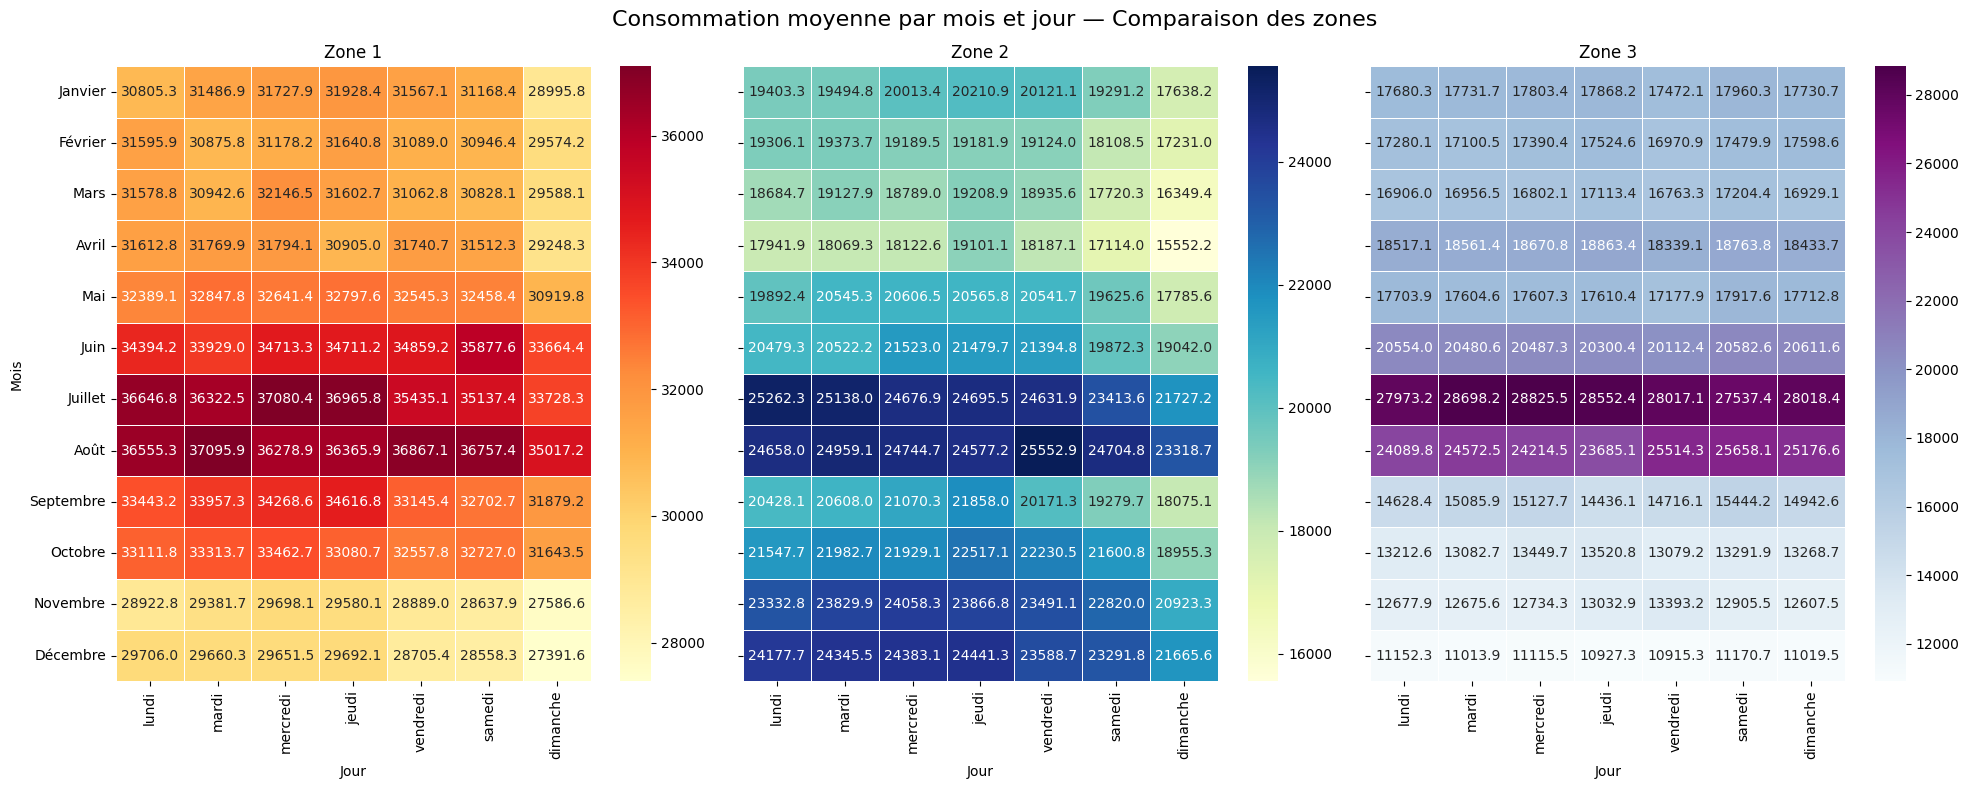

In [45]:

jours_ordre = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
mois_ordre = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
              "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]

data['Jour'] = pd.Categorical(data['Jour'], categories=jours_ordre, ordered=True)
data['Mois'] = pd.Categorical(data['Mois'], categories=mois_ordre, ordered=True)



# 1. Creer un dataset par zone
heat_data = data.groupby(['Mois', 'Jour'], observed=True)['Consommation_Zone_1 kW'].mean().unstack()
heat_data2 = data.groupby(['Mois', 'Jour'], observed=True)['Consommation_Zone_2 kW'].mean().unstack()
heat_data3 = data.groupby(['Mois', 'Jour'], observed=True)['Consommation_Zone_3 kW'].mean().unstack()

#
heat_data = heat_data.loc[mois_ordre, jours_ordre]
heat_data2 = heat_data2.loc[mois_ordre, jours_ordre]
heat_data3 = heat_data3.loc[mois_ordre, jours_ordre]


fig, axes = plt.subplots(1, 3, figsize=(20, 8), sharey=True)

# 3. Plot heatmaps
sns.heatmap(heat_data, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=.5, ax=axes[0])
axes[0].set_title("Zone 1")
axes[0].set_xlabel("Jour")
axes[0].set_ylabel("Mois")

sns.heatmap(heat_data2, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5, ax=axes[1])
axes[1].set_title("Zone 2")
axes[1].set_xlabel("Jour")
axes[1].set_ylabel("")

sns.heatmap(heat_data3, annot=True, fmt=".1f", cmap="BuPu", linewidths=.5, ax=axes[2])
axes[2].set_title("Zone 3")
axes[2].set_xlabel("Jour")
axes[2].set_ylabel("")


plt.suptitle("Consommation moyenne par mois et jour — Comparaison des zones", fontsize=16)
plt.tight_layout()
plt.show()


Les heatmap résume bien les résultats statistiques obtenus. La consommation varie en fonction des mois de l'année et des jours de la semaine, les mois ayant une influence plus forte. Les mois de Juin, Juillet et Août enregistrent les consommations énergétiques les plus importantes pour toutes les zones confondues. Ce qui est normal puisque en été la population à tendance consommer beaucoup plus d'énergie due à la chaleur. En effet nous avons observé dans la partie descriptive une augmentation de la température durant cette période. La zone 2 en particulier consomme aussi beaucoup d'énergie pour les mois de Novembre et décembre. L'évolution de la consommation hebdomadaire suggère une baisse légère pendant les week-ends, plus notable pour les zones 1 et 2. Cela peut s'expliquer par une baisse des activités économique durant le week-end et donc baisse de la consommation.

Vérifions si l'heure impacte la consommation
Hypothèse: Les heures de journée influencent la consommation énergétiques


In [46]:
#from scipy.stats import f_oneway

cons_h = [data[data['Heure'] == h]['Consommation_Zone_1 kW'] for h in range(24)]
f_stat7, pval7 = f_oneway(*cons_h)
print(f"F = {f_stat7:.2f}, p = {pval7:.4f}")

cons_h2 = [data[data['Heure'] == h]['Consommation_Zone_2 kW'] for h in range(24)]
f_stat8, pval8 = f_oneway(*cons_h2)
print(f"F = {f_stat8:.2f}, p = {pval8:.4f}")

cons_h3 = [data[data['Heure'] == h]['Consommation_Zone_3 kW'] for h in range(24)]
f_stat9, pval9 = f_oneway(*cons_h3)
print(f"F = {f_stat9:.2f}, p = {pval9:.4f}")

#Créons un dataframe avec les résultats

anova_results3 = pd.DataFrame({
    "Zone": ["Zone 1", "Zone 2", "Zone 3"],
    "F-statistique": [f_stat7, f_stat8, f_stat9],
    "P-value": [pval7, pval8, pval9]
})


F = 6674.78, p = 0.0000
F = 3535.86, p = 0.0000
F = 1342.14, p = 0.0000


In [47]:
anova_results3

,Zone,F-statistique,P-value
0,Zone 1,6674.779123,0.0
1,Zone 2,3535.857985,0.0
2,Zone 3,1342.136357,0.0


Ces résultats montrent que partout la consommation change considérablement selon l’heure. La zone 1 a une très forte dépendance à l’heure probablement due à une activité économique intense et une large population étant donné que dans l'analyse descriptive nous avons noté que la zone 1 enregistre un consommation moyenne très supérieure aux autres et ceci durant toute l'année

Repérons les conditions ce qui se passent autour des pics. Pouer cela définissons d'abord les pics.

In [48]:
# 10% des valeurs les plus eleves
seuil = data['Consommation_Zone_1 kW'].quantile(0.90)
data['Pic_zone1'] = data['Consommation_Zone_1 kW'] > seuil

seuil2 = data['Consommation_Zone_1 kW'].quantile(0.90)
data['Pic_zone2'] = data['Consommation_Zone_2 kW'] > seuil2

seuil3 = data['Consommation_Zone_1 kW'].quantile(0.90)
data['Pic_zone3'] = data['Consommation_Zone_3 kW'] > seuil3


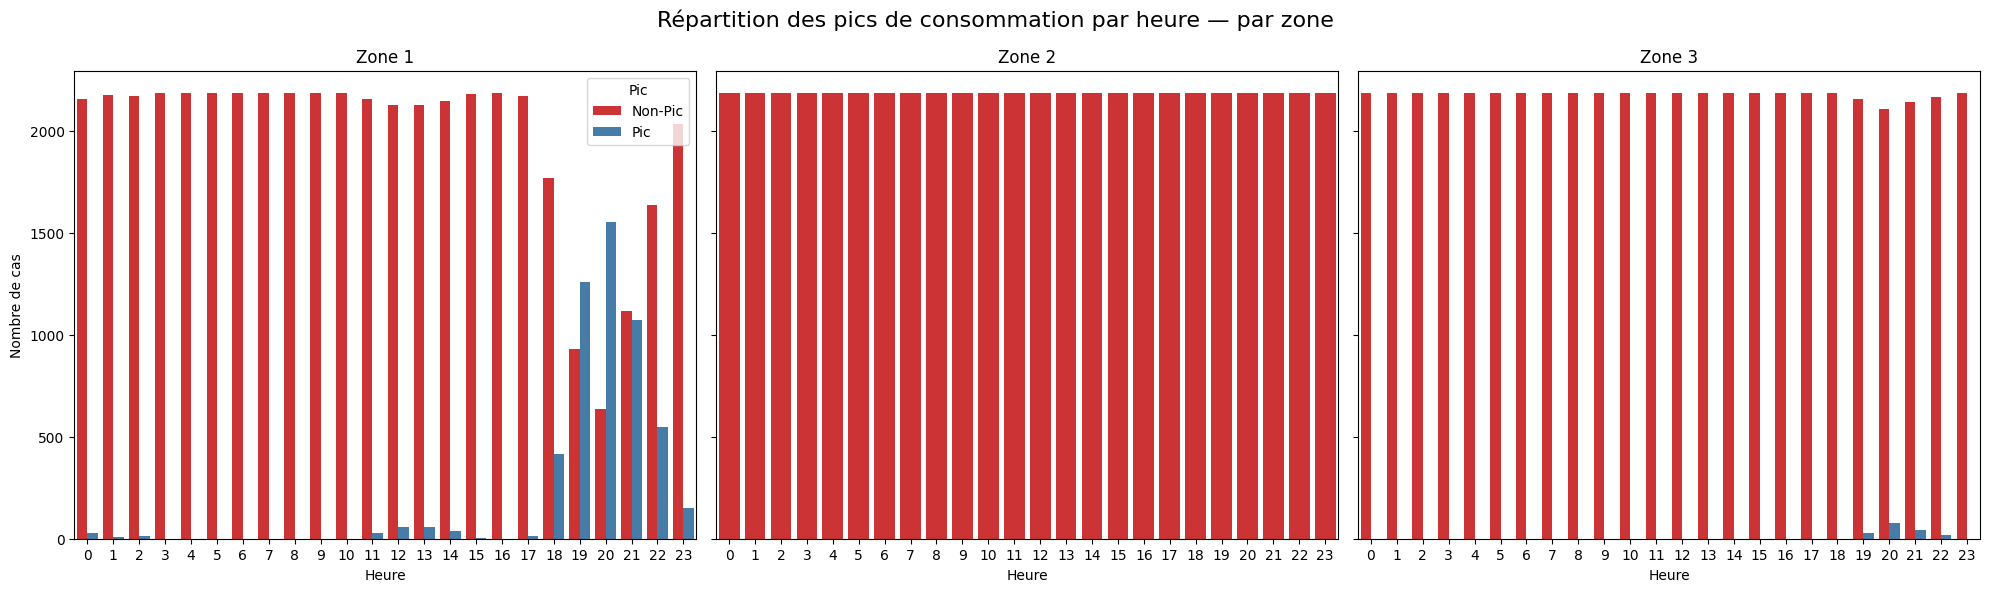

In [49]:



fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

# Zone 1
sns.countplot(x='Heure', hue='Pic_zone1', data=data, ax=axes[0], palette='Set1')
axes[0].set_title("Zone 1")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Nombre de cas")
axes[0].legend(title="Pic", labels=["Non-Pic", "Pic"])

# Zone 2
sns.countplot(x='Heure', hue='Pic_zone2', data=data, ax=axes[1], palette='Set1')
axes[1].set_title("Zone 2")
axes[1].set_xlabel("Heure")
axes[1].set_ylabel("")
axes[1].legend([],[], frameon=False)  # Remove duplicate legend

# Zone 3
sns.countplot(x='Heure', hue='Pic_zone3', data=data, ax=axes[2], palette='Set1')
axes[2].set_title("Zone 3")
axes[2].set_xlabel("Heure")
axes[2].set_ylabel("")
axes[2].legend([],[], frameon=False)




plt.suptitle("Répartition des pics de consommation par heure — par zone", fontsize=16)
plt.tight_layout()
plt.show()


Ayant noté que les valeurs de consommation sont très différentes pour chaque zone, ce qui impacte la visualisation comme le montre le graph ci-dessus. Nous allons redéfinir certains Pics.

In [50]:
seuil2 = data['Consommation_Zone_1 kW'].quantile(0.65)
data['Pic_zone2'] = data['Consommation_Zone_2 kW'] > seuil2

seuil3 = data['Consommation_Zone_1 kW'].quantile(0.80)
data['Pic_zone3'] = data['Consommation_Zone_3 kW'] > seuil3


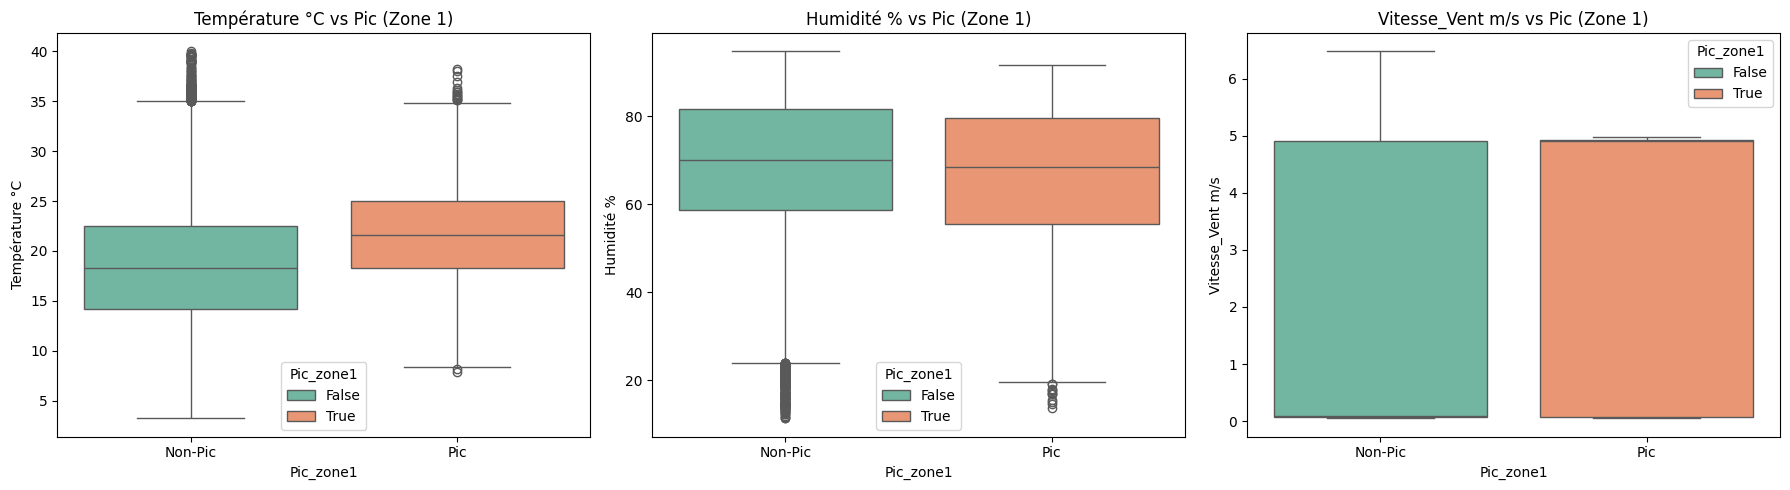

Température °C: t-stat=37.81, p-value=0.0000
Humidité %: t-stat=-10.43, p-value=0.0000
Vitesse_Vent m/s: t-stat=19.31, p-value=0.0000


In [ ]:
# Definissons les pics et non pic
pic_data = data[data["Pic_zone1"] == True]
non_pic_data = data[data["Pic_zone1"] == False]

# On utilisera les variables suivantes
pic_data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Heure"]].describe()
non_pic_data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Heure"]].describe()


# Nous voulons ici les graph cote a cote

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
variables = ["Température °C", "Humidité %", "Vitesse_Vent m/s"]

for i, var in enumerate(variables):
    sns.boxplot(x="Pic_zone1", hue="Pic_zone1", y=var, data=data, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{var} vs Pic (Zone 1)")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Non-Pic", "Pic"])

plt.tight_layout()
plt.show()


# Assurons nous d'avoir des valeurs adéquate pour les pics


from scipy.stats import ttest_ind

for var in ["Température °C", "Humidité %", "Vitesse_Vent m/s"]:
    t_stat, p = ttest_ind(
        data[data["Pic_zone1"] == True][var],
        data[data["Pic_zone1"] == False][var],
        equal_var=False
    )
    print(f"{var}: t-stat={t_stat:.2f}, p-value={p:.4f}")



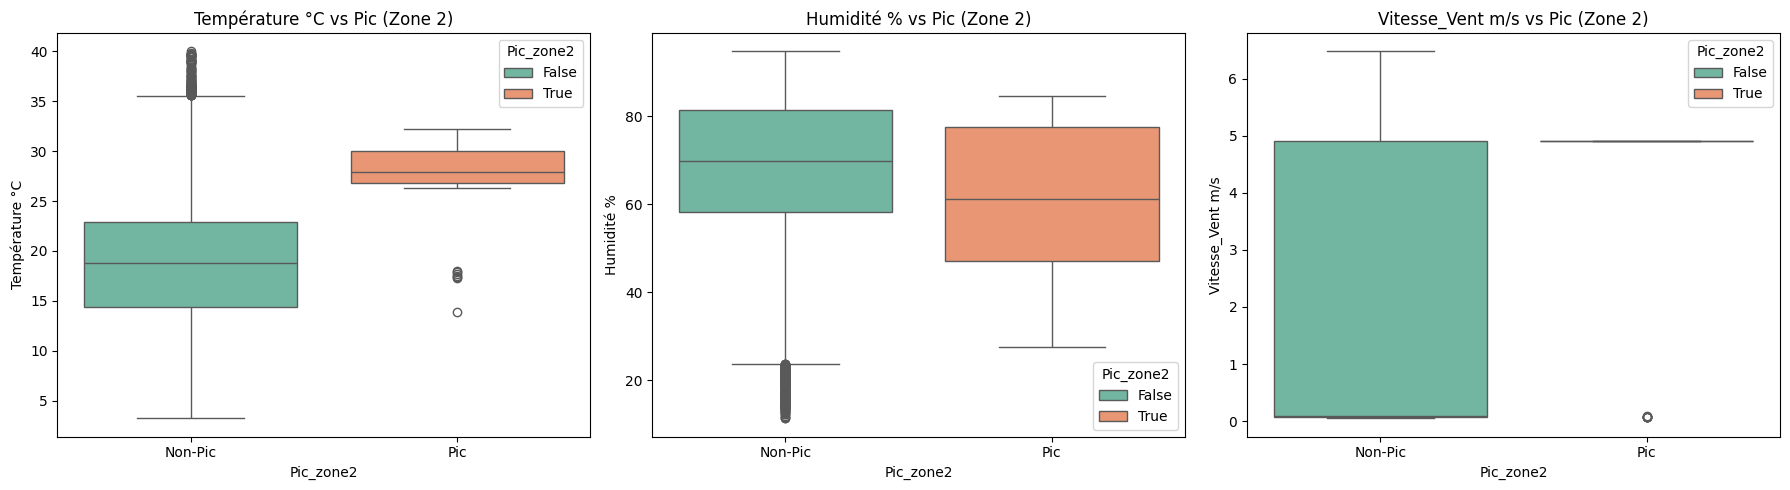

Température °C: t-stat = 14.69, p-value = 0.0000
Humidité %: t-stat = -3.26, p-value = 0.0019
Vitesse_Vent m/s: t-stat = 10.63, p-value = 0.0000


In [ ]:

pic_data = data[data["Pic_zone2"] == True]
non_pic_data = data[data["Pic_zone2"] == False]


pic_data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Heure"]].describe()
non_pic_data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Heure"]].describe()

# Essayons de visualiser les variables au moment des pics

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
variables = ["Température °C", "Humidité %", "Vitesse_Vent m/s"]

for i, var in enumerate(variables):
    sns.boxplot(x="Pic_zone2", y=var, hue="Pic_zone2", data=data, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{var} vs Pic (Zone 2)")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Non-Pic", "Pic"])

plt.tight_layout()
plt.show()


# verifions que maintenant on des valeurs adequates pour les pics
from scipy.stats import ttest_ind

for var in ["Température °C", "Humidité %", "Vitesse_Vent m/s"]:
    group_peak = data[data["Pic_zone2"] == True][var].dropna()
    group_non_peak = data[data["Pic_zone2"] == False][var].dropna()
    
    if len(group_peak) > 1 and len(group_non_peak) > 1:
        t_stat, p = ttest_ind(group_peak, group_non_peak, equal_var=False)
        print(f"{var}: t-stat = {t_stat:.2f}, p-value = {p:.4f}")
    else:
        print(f"{var}: Pas assez de données pour le test t (taille: Pic={len(group_peak)}, Non-Pic={len(group_non_peak)})")



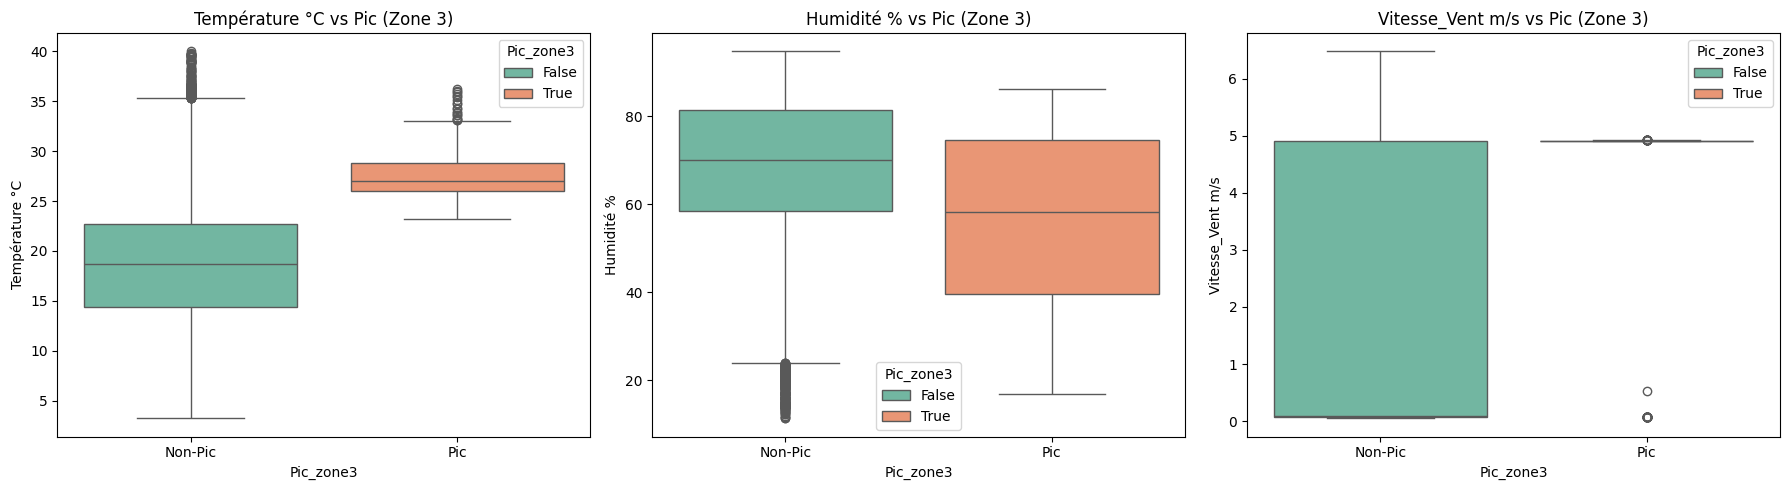

Température °C: t-stat=81.63, p-value=0.0000
Humidité %: t-stat=-14.14, p-value=0.0000
Vitesse_Vent m/s: t-stat=45.66, p-value=0.0000


In [ ]:

pic_data = data[data["Pic_zone3"] == True]
non_pic_data = data[data["Pic_zone3"] == False]



pic_data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Heure"]].describe()
non_pic_data[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Heure"]].describe()


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
variables = ["Température °C", "Humidité %", "Vitesse_Vent m/s"]

for i, var in enumerate(variables):
    sns.boxplot(x="Pic_zone3", y=var, hue="Pic_zone3", data=data, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{var} vs Pic (Zone 3)")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Non-Pic", "Pic"])

plt.tight_layout()
plt.show()


from scipy.stats import ttest_ind

for var in ["Température °C", "Humidité %", "Vitesse_Vent m/s"]:
    t_stat, p = ttest_ind(
        data[data["Pic_zone3"] == True][var],
        data[data["Pic_zone3"] == False][var],
        equal_var=False
    )
    print(f"{var}: t-stat={t_stat:.2f}, p-value={p:.4f}")



Résumons pour les trois zones
**Interprétations** :
Lorsqu’il fait chaud, la consommation augmente fortement (climatisation, refroidissement industriel, etc.).
L' humidité contribue à l’inconfort thermique et donc besoin de rafraîchissement. Le vent contribue faiblement.

Les résultats montrent que les pics de consommation énergétique ne sont pas aléatoires.Ils sont liés à des conditions météorologiques spécifiques, en particulier la température.

## **ETAPE 4 ANALYSE PREDICTIVE** 

Objectif: Essayer de construire un modèle de prevision de la consommation énergetique en fonction des conditions météorologiques et le temps (jour, mois, heure)

Commençons avec un régression linéaire multiple aves les valeurs quantitatives.

R²: 0.6299895339695183
Erreur quadratique moyenne: 4322.436859024713
Coefficients: [2282.47172872   38.94192761  103.83271305 -451.71004541  -61.92860512
 4829.84269183]


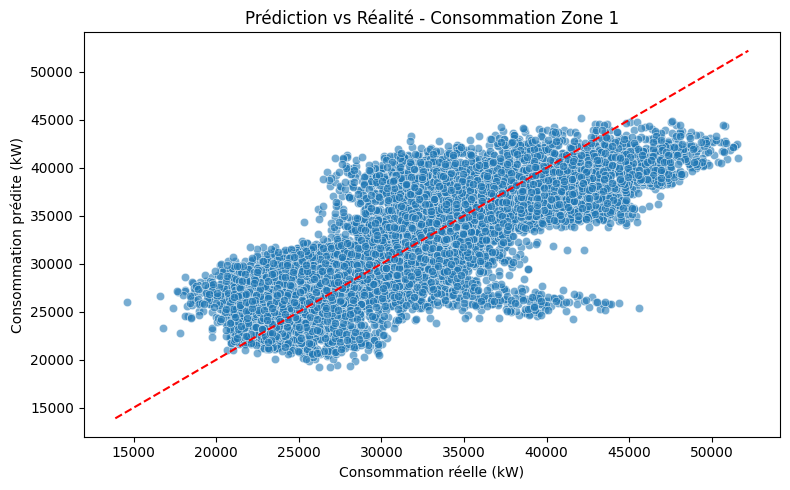

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


# 1. Variables
X = data_scaled[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y = data_scaled["Consommation_Zone_1 kW"]

# 2. Division en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Modèle
model_7 = LinearRegression()
model_7.fit(X_train, y_train)

# 4. Prédiction
y_pred = model_7.predict(X_test)

# 5. Affichage des performances
print("R²:", r2_score(y_test, y_pred))
print("Erreur quadratique moyenne:", mean_squared_error(y_test, y_pred)**0.5)
print("Coefficients:", model_7.coef_)

# 6. Visualisation : consommation réelle vs prédite
plt.figure(figsize=(8,5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.xlabel("Consommation réelle (kW)")
plt.ylabel("Consommation prédite (kW)")
plt.title("Prédiction vs Réalité - Consommation Zone 1")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  
plt.tight_layout()
plt.show()




R² = 0.62 La régression explique environ 62% de la variabilité de la consommation, donc assez considérable
Erreur quadratique moyenne (RMSE) = 4322 kW  donc relativement importante par rapport à l’échelle de consommation

R²: 0.518552652277495
Erreur quadratique moyenne: 3604.7322709875284
Coefficients: [1295.48101456 -301.51940584  108.59613038 -472.28265143  -75.54199343
 3202.59886229]


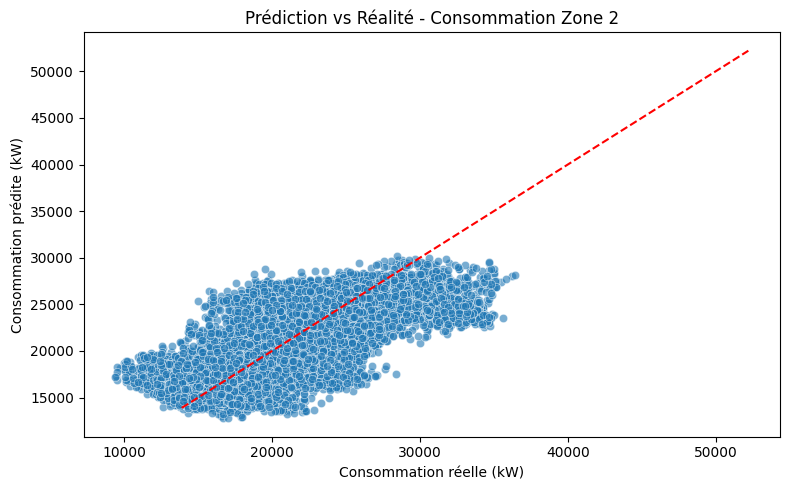

In [ ]:


# 1. Variables
X5 = data_scaled[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y5 = data["Consommation_Zone_2 kW"]

# 2. Division en train/test
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.2, random_state=42)

# 3. Modèle
model_8 = LinearRegression()
model_8.fit(X5_train, y5_train)

# 4. Prédiction
y5_pred = model_8.predict(X5_test)

# 5. Affichage des performances
print("R²:", r2_score(y5_test, y5_pred))
print("Erreur quadratique moyenne:", mean_squared_error(y5_test, y5_pred)**0.5)
print("Coefficients:", model_8.coef_)

# 6. Visualisation : consommation réelle vs prédite
plt.figure(figsize=(8,5))
sns.scatterplot(x=y5_test, y=y5_pred, alpha=0.6)
plt.xlabel("Consommation réelle (kW)")
plt.ylabel("Consommation prédite (kW)")
plt.title("Prédiction vs Réalité - Consommation Zone 2")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  
plt.tight_layout()
plt.show()




R²: 0.518552652277495
Erreur quadratique moyenne: 3604.7322709875284
Coefficients: [1295.48101456 -301.51940584  108.59613038 -472.28265143  -75.54199343
 3202.59886229]
Le R² est plus faible donc n'explique que 51% de la variance donc ici le modèle n'est pas adapté aux données.

R²: 0.41956969217215945
Erreur quadratique moyenne: 5030.844504180582
Coefficients: [ 3080.86515604   -79.3034655    498.67599048  -596.59652426
 -1101.34018146  2624.16523857]


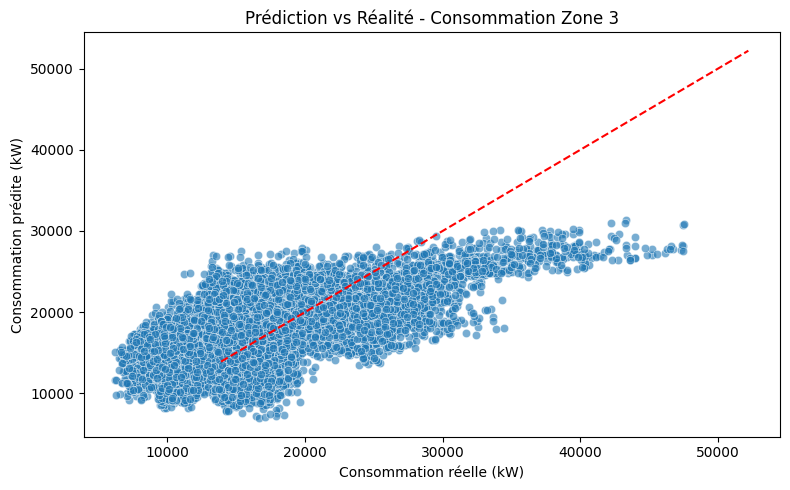

In [ ]:


# 1. Variables
X6 = data_scaled[["Température °C", "Humidité %", "Vitesse_Vent m/s", "Flux_Diffus W/m²", "Flux_Diffus_Généraux W/m²", "Heure"]]
y6 = data_scaled["Consommation_Zone_3 kW"]

# 2. Division en train/test
X6_train, X6_test, y6_train, y6_test = train_test_split(X6, y6, test_size=0.2, random_state=42)

# 3. Modèle
model_9 = LinearRegression()
model_9.fit(X6_train, y6_train)

# 4. Prédiction
y6_pred = model_9.predict(X6_test)

# 5. Affichage des performances
print("R²:", r2_score(y6_test, y6_pred))
print("Erreur quadratique moyenne:", mean_squared_error(y6_test, y6_pred)**0.5)
print("Coefficients:", model_9.coef_)

# 6. Visualisation : consommation réelle vs prédite
plt.figure(figsize=(8,5))
sns.scatterplot(x=y6_test, y=y6_pred, alpha=0.6)
plt.xlabel("Consommation réelle (kW)")
plt.ylabel("Consommation prédite (kW)")
plt.title("Prédiction vs Réalité - Consommation Zone 3")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  
plt.tight_layout()
plt.show()




R²: 0.41956969217215945
Erreur quadratique moyenne: 5030.844504180582
Coefficients: [ 3080.86515604   -79.3034655    498.67599048  -596.59652426
 -1101.34018146  2624.16523857]
Le R² est encore plus faible pour la zone 3, et le modèle n'explique que 41% de la variance. Les points sont encore plus éloignés de la droite de regression. 

In [57]:
data.head()

,Température °C,Humidité %,Vitesse_Vent m/s,Flux_Diffus_Généraux W/m²,Flux_Diffus W/m²,Consommation_Zone_1 kW,Consommation_Zone_2 kW,Consommation_Zone_3 kW,Jour,Mois,Heure,Pic_zone1,Pic_zone2,Pic_zone3
0,6.559,73.8,0.083,0.051,0.119,34056,16129,20241,dimanche,Janvier,0,False,False,False
1,6.414,74.5,0.083,0.070,0.085,29815,19375,20131,dimanche,Janvier,0,False,False,False
2,6.313,74.5,0.080,0.062,0.100,29128,19007,19668,dimanche,Janvier,0,False,False,False
3,6.121,75.0,0.083,0.091,0.096,28229,18361,18899,dimanche,Janvier,0,False,False,False
4,5.921,75.7,0.081,0.048,0.085,27336,17872,18442,dimanche,Janvier,0,False,False,False


On supprime les Pics pour éviter qu'il n'interfère avec le rest de l'analyse.

In [58]:
data=data.drop(["Pic_zone1", "Pic_zone2", "Pic_zone2"], axis=1)

Voyant que la régression nous a fourni un modèle de prédiction pas très adapté, ce qui peut être du au fait que nos variables ne suivent pas une tendance linéaire comme nous l'avons vu dans la partie descriptive. La regression linéaire multiple est utile mais très limitée dans notre cas. Ainsi nous allons aussi utiliser Random forest pour voir si on obtient un meilleur modèle.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Encodage one-hot des colonnes catégorielles
data_dummies = pd.get_dummies(data, columns=["Jour", "Mois", "Heure"], drop_first=True)


X = data_dummies.drop(columns=["Consommation_Zone_1 kW", "Consommation_Zone_2 kW", "Consommation_Zone_3 kW"])
y = data_dummies["Consommation_Zone_1 kW"]

# Séparation en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modèle
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prédictions
y_pred = rf_model.predict(X_test)

# Évaluation
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² : {r2:.4f}")
print(f"RMSE : {rmse:.2f}")



R² : 0.9761
RMSE : 1098.11


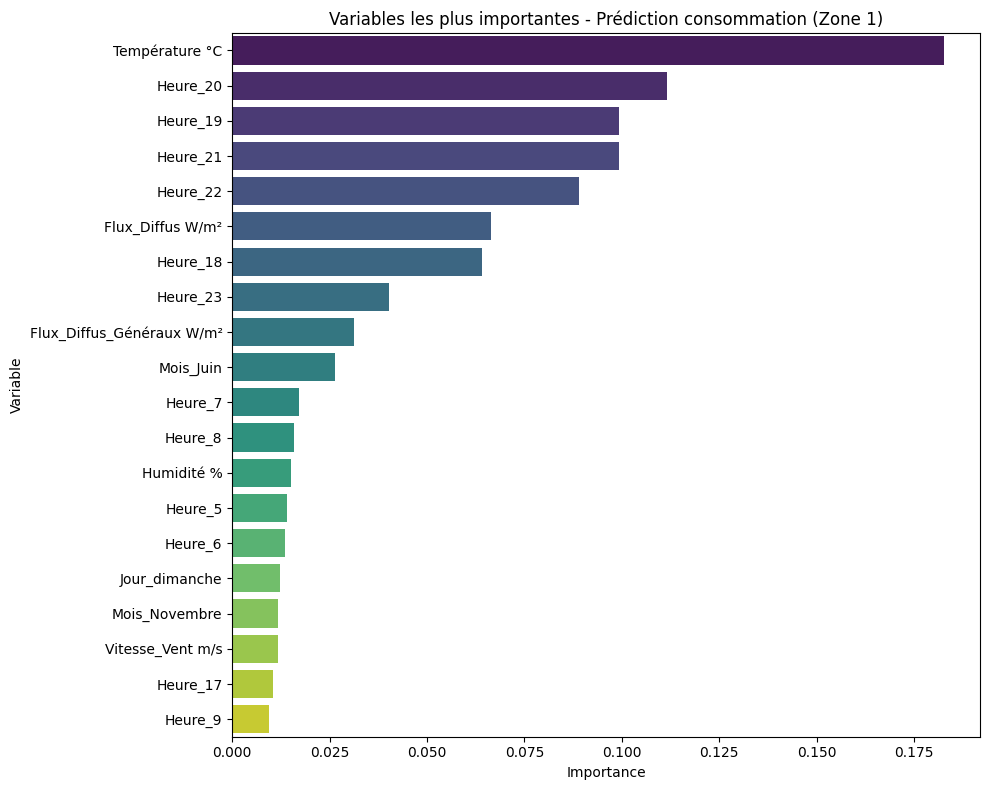

In [60]:
#IMPORTANCE DES VARIABLES

# Récupération des importances
importances = rf_model.feature_importances_
feature_names = X.columns

# Création d’un DataFrame
importance_df1 = pd.DataFrame({
    "Variable": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Visualisation
plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df1.head(20), x="Importance", y="Variable", hue="Variable", palette="viridis", legend=False)
plt.title("Variables les plus importantes - Prédiction consommation (Zone 1)")
plt.tight_layout()
plt.show()

R² : 0.9768
RMSE : 792.02


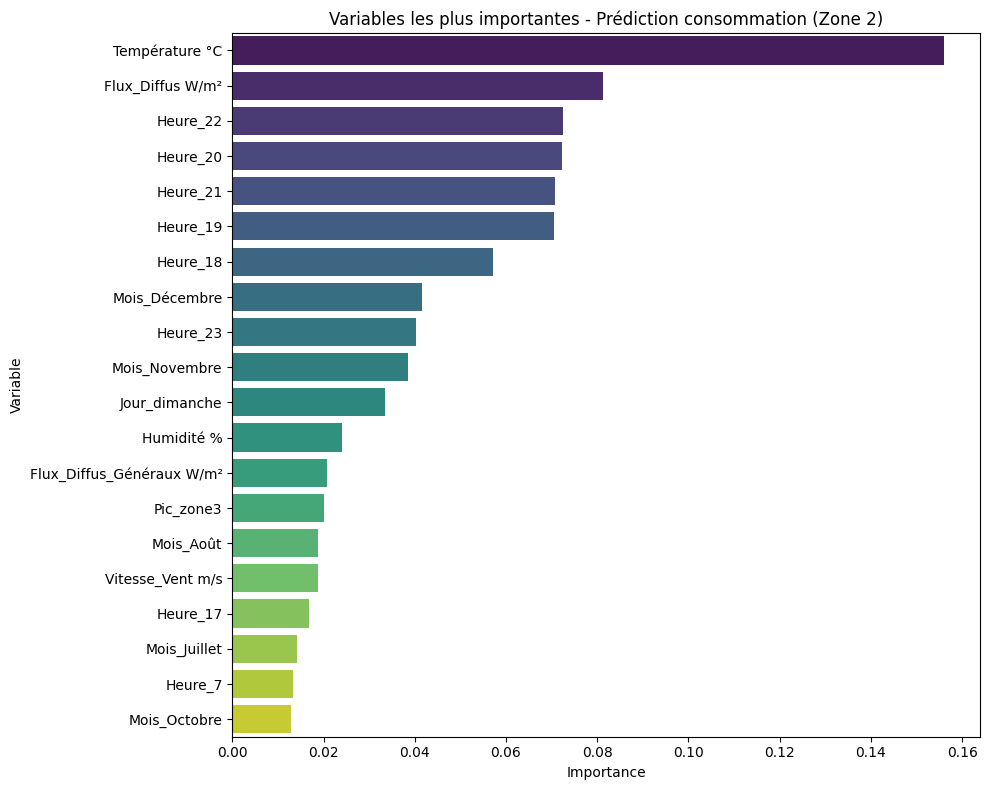

In [ ]:

# Données explicatives et cible (Zone 1 ici, répéter pour 2 et 3)
X = data_dummies.drop(columns=["Consommation_Zone_1 kW", "Consommation_Zone_2 kW", "Consommation_Zone_3 kW"])
y = data_dummies["Consommation_Zone_2 kW"]

# Séparation en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modèle
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prédictions
y_pred = rf_model.predict(X_test)

# Évaluation
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² : {r2:.4f}")
print(f"RMSE : {rmse:.2f}")


# Récupération des importances
importances = rf_model.feature_importances_
feature_names = X.columns

# Création d’un DataFrame
importance_df2 = pd.DataFrame({
    "Variable": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Visualisation
plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df2.head(20), x="Importance", y="Variable", hue="Variable", palette="viridis", legend=False)
plt.title("Variables les plus importantes - Prédiction consommation (Zone 2)")
plt.tight_layout()
plt.show()


R² : 0.9860
RMSE : 781.84


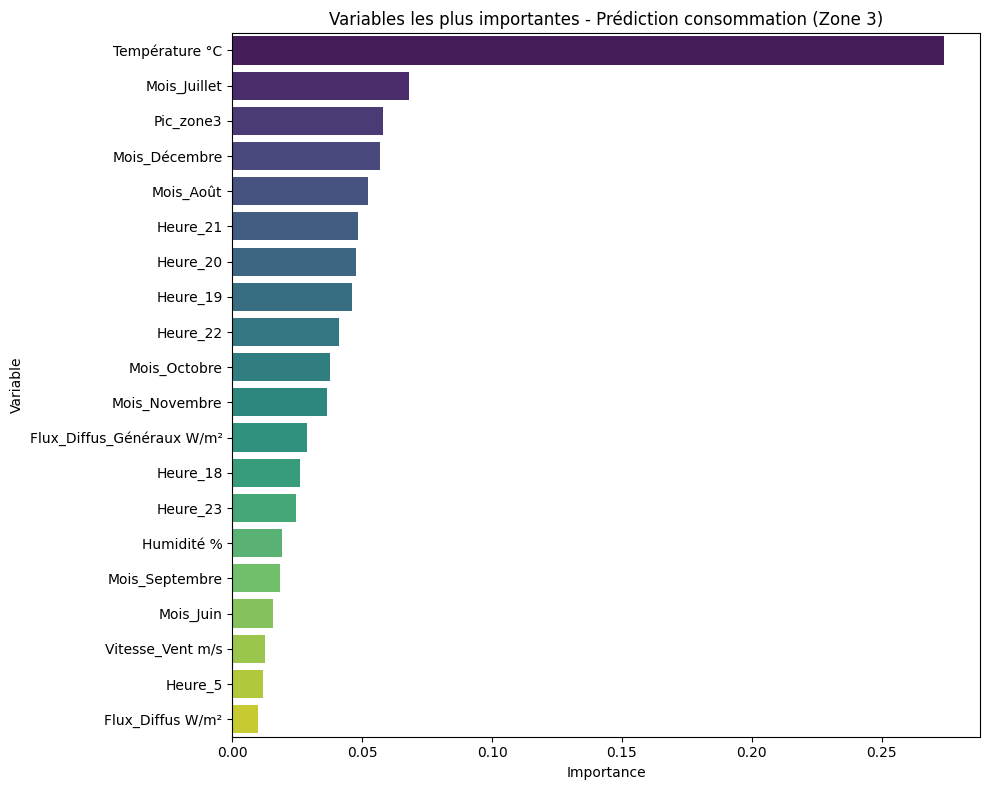

In [ ]:

# Données explicatives et cible (Zone 1 ici, répéter pour 2 et 3)
X = data_dummies.drop(columns=["Consommation_Zone_1 kW", "Consommation_Zone_2 kW", "Consommation_Zone_3 kW"])
y = data_dummies["Consommation_Zone_3 kW"]

# Séparation en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modèle
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prédictions
y_pred = rf_model.predict(X_test)

# Évaluation
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² : {r2:.4f}")
print(f"RMSE : {rmse:.2f}")



# Récupération des importances
importances = rf_model.feature_importances_
feature_names = X.columns

# Création d’un DataFrame
importance_df3 = pd.DataFrame({
    "Variable": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Visualisation
plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df3.head(20), x="Importance", y="Variable", hue="Variable", palette="viridis", legend=False)
plt.title("Variables les plus importantes - Prédiction consommation (Zone 3)")
plt.tight_layout()
plt.show()


Contrairement à la régression linéaire, le modèle Random Forest fournit des résultats beaucoup plus satisfaisants pour la prédiction de la consommation énergétique des trois zones.

Les coefficients de détermination R² sont très élevés :

Zone 1 : R² = **0.9732**
Zone 2 : R² = **0.9684**
Zone 3 : R² = **0.9854**

Cela signifie que le modèle explique entre 96 % et 98 %  à peu près de la variabilité de la consommation énergétique.
Les valeurs de l’erreur quadratique moyenne (RMSE) sont très basses :

Zone 1 : **1163.54 kW**
Zone 2 : **923.33 kW**
Zone 3 : **796.59 kW**

Cela montre que les écarts entre les consommations réelles et prédites sont faibles, y compris en présence de pics dans les données.

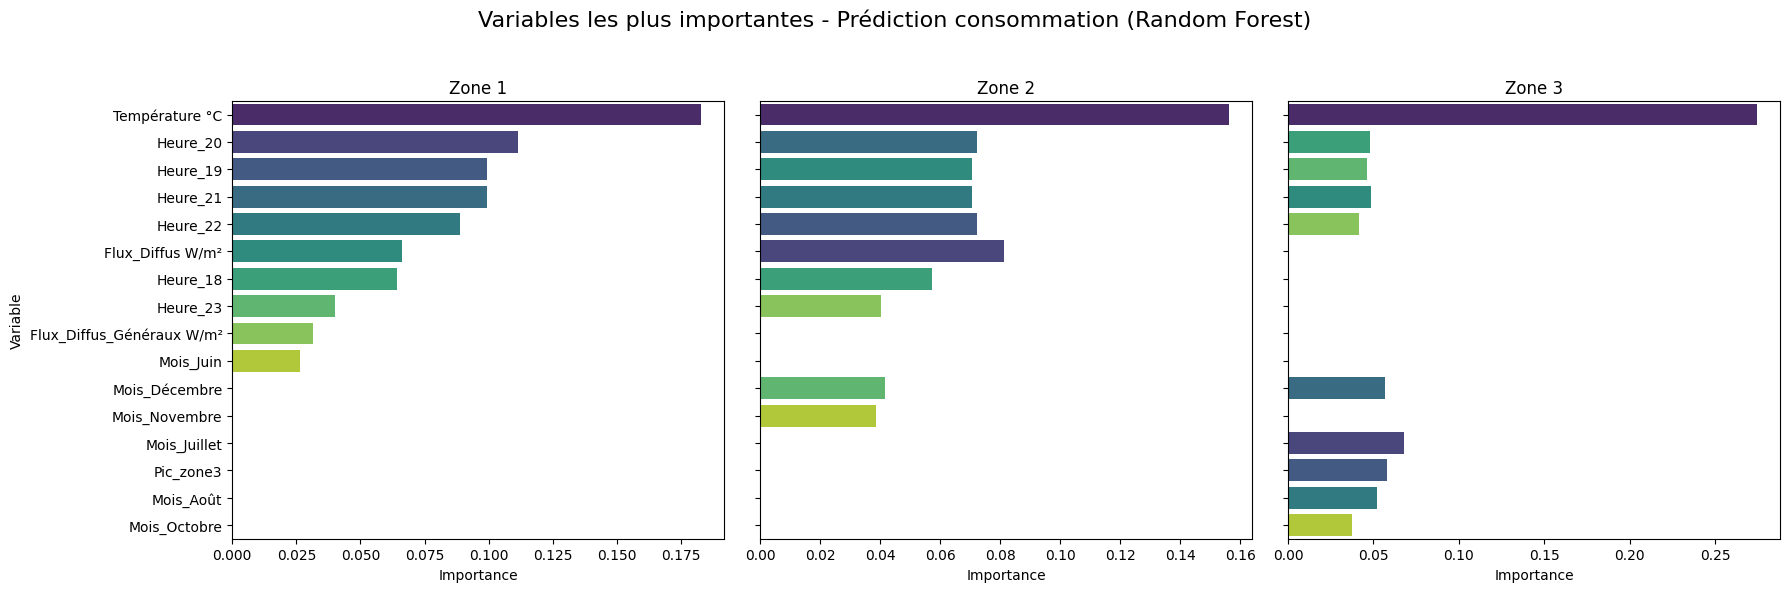

In [ ]:

# Visualisons les résultats cote à cote

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Zone 1
sns.barplot(
    data=importance_df1.sort_values(by="Importance", ascending=False).head(10),
    x="Importance", y="Variable", hue="Variable", palette="viridis", legend=False,  ax=axes[0]
)
axes[0].set_title("Zone 1")
axes[0].set_xlabel("Importance")
axes[0].set_ylabel("Variable")

# Zone 2
sns.barplot(
    data=importance_df2.sort_values(by="Importance", ascending=False).head(10),
    x="Importance", y="Variable", hue="Variable", palette="viridis", legend=False, ax=axes[1]
)
axes[1].set_title("Zone 2")
axes[1].set_xlabel("Importance")
axes[1].set_ylabel("")

# Zone 3
sns.barplot(
    data=importance_df3.sort_values(by="Importance", ascending=False).head(10),
    x="Importance", y="Variable", hue="Variable", palette="viridis", legend=False, ax=axes[2]
)
axes[2].set_title("Zone 3")
axes[2].set_xlabel("Importance")
axes[2].set_ylabel("")

# Ajustements
plt.suptitle("Variables les plus importantes - Prédiction consommation (Random Forest)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## **ETAPE 5: ANALYSE PRESCRIPTIVE** 

Objectif: Fournir des recommendations a partir des informations obtenues des analyses

Ce qu'on retient est que la consommation énergetique n'est pas la même pour toute les zones.
- La **zone 1** consomme beaucoup plus et est très sensible aux horaires de la journées. Ensuite vient la température et la période de l'année. Donc la gestion énergetique pour cette zone devra être acès sur une amélioration de l'approvisionnement surtout en journée, les jours ouvrables et les mois d'été. 

- La **zone 2** consomme moins mais est susceptible aux même conditions qui font varier la consommation dans la zone 2, sauf que pour les mois de Novembre et décembre, la consommation égale celle des mois d'été. Donc c'est une information à prendre en compte par les distributeurs d'energie. 

- La consommation en **zone 3** est encore beaucoup plus faible et cette partie de la ville est moins influencé par les horaires. Ce qui peut être à une activité moins importante dans cette zone. Néanmoins c'est la même tendance que les autres zone lorsqu'il s'agit des mois plus chauds à savoir entre Juin et Septembre.